# Steel Industry Energy — Phase 2: Consumption Patterns & Phase 3: Efficiency Analysis

**Dataset:** DAEWOO Steel Co. Ltd — 35,040 rows · 15-minute intervals · 1 calendar year  
**Scope:** Descriptive and diagnostic analysis only. No prediction. No ML.

---
## 1. Load Data

In [1]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

zip_path = 'Steel_industry_data.csv.zip'
with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(z.namelist()[0]) as f:
        df = pd.read_csv(f)

print('Dataset loaded successfully.')

Dataset loaded successfully.


---
## 2. View Data Visually

In [2]:
# First 5 rows
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


In [3]:
# Last 5 rows
df.tail()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
35035,31/12/2018 23:00,3.85,4.86,0.00,0.0,62.10,100.00,82800,Weekday,Monday,Light_Load
35036,31/12/2018 23:15,3.74,3.74,0.00,0.0,70.71,100.00,83700,Weekday,Monday,Light_Load
35037,31/12/2018 23:30,3.78,3.17,0.07,0.0,76.62,99.98,84600,Weekday,Monday,Light_Load
35038,31/12/2018 23:45,3.78,3.06,0.11,0.0,77.72,99.96,85500,Weekday,Monday,Light_Load
35039,31/12/2018 00:00,3.67,3.02,0.07,0.0,77.22,99.98,0,Weekday,Monday,Light_Load


In [4]:
# Random 5 rows
df.sample(5)

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
13879,25/05/2018 14:00,51.59,23.54,0.00,0.02,90.98,100.00,50400,Weekday,Friday,Maximum_Load
4889,20/02/2018 22:30,72.00,37.66,0.00,0.03,88.61,100.00,81000,Weekday,Tuesday,Maximum_Load
27696,16/10/2018 12:15,13.75,2.81,12.56,0.01,97.97,73.83,44100,Weekday,Tuesday,Medium_Load
23060,29/08/2018 05:15,2.77,4.75,0.00,0.00,50.38,100.00,18900,Weekday,Wednesday,Light_Load
5744,01/03/2018 20:15,5.36,0.00,27.54,0.00,100.00,19.10,72900,Weekday,Thursday,Medium_Load


---
## 3. Inspect Data Programmatically

In [5]:
print('Shape:', df.shape)

Shape: (35040, 11)


In [6]:
print('Columns:')
print(df.columns.tolist())

Columns:
['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']


In [7]:
df.dtypes

date                                     object
Usage_kWh                               float64
Lagging_Current_Reactive.Power_kVarh    float64
Leading_Current_Reactive_Power_kVarh    float64
CO2(tCO2)                               float64
Lagging_Current_Power_Factor            float64
Leading_Current_Power_Factor            float64
NSM                                       int64
WeekStatus                               object
Day_of_week                              object
Load_Type                                object
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  object 
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  object 
 9   Day_of_week                           35040 non-null  object 
 10  Load_Type                             35040 non-null  object 
dtypes: float64(6), 

In [9]:
# Numeric columns summary
df.describe()

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000
mean,27.386892,13.035384,3.870949,0.011524,80.578056,84.367870,42750.000000
std,33.444380,16.306000,7.424463,0.016151,18.921322,30.456535,24940.534317
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.200000,2.300000,0.000000,0.000000,63.320000,99.700000,21375.000000
50%,4.570000,5.000000,0.000000,0.000000,87.960000,100.000000,42750.000000
75%,51.237500,22.640000,2.090000,0.020000,99.022500,100.000000,64125.000000
max,157.180000,96.910000,27.760000,0.070000,100.000000,100.000000,85500.000000


In [10]:
# Categorical columns summary
df.describe(include='object')

,date,WeekStatus,Day_of_week,Load_Type
count,35040,35040,35040,35040
unique,35040,2,7,3
top,01/01/2018 00:15,Weekday,Monday,Light_Load
freq,1,25056,5088,18072


In [11]:
# Value counts per categorical column
cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    print(f'\n"{col}" — {df[col].nunique()} unique values:')
    print(df[col].value_counts())


"date" — 35040 unique values:
date
01/01/2018 00:15    1
01/09/2018 08:45    1
01/09/2018 07:15    1
01/09/2018 07:30    1
01/09/2018 07:45    1
                   ..
02/05/2018 14:45    1
02/05/2018 14:30    1
02/05/2018 14:15    1
02/05/2018 14:00    1
31/12/2018 00:00    1
Name: count, Length: 35040, dtype: int64

"WeekStatus" — 2 unique values:
WeekStatus
Weekday    25056
Weekend     9984
Name: count, dtype: int64

"Day_of_week" — 7 unique values:
Day_of_week
Monday       5088
Tuesday      4992
Wednesday    4992
Thursday     4992
Friday       4992
Saturday     4992
Sunday       4992
Name: count, dtype: int64

"Load_Type" — 3 unique values:
Load_Type
Light_Load      18072
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64


---
## 4. Identify Quality Issues

In [12]:
# QI-1: Missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
result = pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})
result = result[result['missing_count'] > 0]

if result.empty:
    print('No missing values found.')
else:
    print('ISSUE — Missing values:')
    print(result)

No missing values found.


In [13]:
# QI-2: Duplicate rows
dups = df.duplicated().sum()
if dups > 0:
    print(f'ISSUE — {dups} duplicate rows found.')
    print(df[df.duplicated(keep=False)].head(6))
else:
    print('No duplicate rows.')

No duplicate rows.


In [14]:
# QI-3: Wrong data types — date stored as string
date_cols = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()]
for col in date_cols:
    if df[col].dtype == object:
        print(f'ISSUE — "{col}" is dtype object (string), should be datetime.')
        print(f'  Sample values: {df[col].head(3).tolist()}')
    else:
        print(f'"{col}" dtype is already {df[col].dtype}.')

ISSUE — "date" is dtype object (string), should be datetime.
  Sample values: ['01/01/2018 00:15', '01/01/2018 00:30', '01/01/2018 00:45']


In [15]:
# QI-4: Inconsistent formats — whitespace & mixed case in categorical columns
cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    has_whitespace = not (df[col].str.strip() == df[col]).all()
    has_mixed_case = df[col].str.lower().nunique() < df[col].nunique()
    if has_whitespace:
        print(f'ISSUE — "{col}": leading/trailing whitespace found.')
    if has_mixed_case:
        print(f'ISSUE — "{col}": mixed-case entries.')
    if not has_whitespace and not has_mixed_case:
        print(f'"{col}": consistent format.')

"date": consistent format.
"WeekStatus": consistent format.
"Day_of_week": consistent format.
"Load_Type": consistent format.


In [16]:
# QI-5: Invalid / unrealistic values + IQR outlier detection
numeric_cols = df.select_dtypes(include='number').columns.tolist()
issues = []

non_neg_cols = [c for c in numeric_cols if any(k in c.lower() for k in ['kwh', 'kvar', 'co2'])]
for col in non_neg_cols:
    n = (df[col] < 0).sum()
    if n:
        issues.append(f'ISSUE — "{col}": {n} negative values (must be >= 0)')

pf_cols = [c for c in numeric_cols if 'factor' in c.lower()]
for col in pf_cols:
    n = ((df[col] < 0) | (df[col] > 100)).sum()
    if n:
        issues.append(f'ISSUE — "{col}": {n} values outside valid range [0, 100]')

if not issues:
    print('No impossible values found.')
else:
    for i in issues:
        print(i)

# IQR outlier detection
outlier_rows = []
for col in numeric_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    if n > 0:
        outlier_rows.append({
            'column': col, 'outliers': n,
            '%': round(n/len(df)*100, 2),
            'IQR_lower': round(lo, 3), 'IQR_upper': round(hi, 3),
            'actual_min': df[col].min(), 'actual_max': df[col].max()
        })

if outlier_rows:
    print('\nISSUE — Outliers (IQR method):')
    print(pd.DataFrame(outlier_rows).to_string(index=False))
else:
    print('\nNo outliers detected.')

No impossible values found.

ISSUE — Outliers (IQR method):
                              column  outliers     %  IQR_lower  IQR_upper  actual_min  actual_max
                           Usage_kWh       328  0.94    -68.856    123.294         0.0      157.18
Lagging_Current_Reactive.Power_kVarh      1059  3.02    -28.210     53.150         0.0       96.91
Leading_Current_Reactive_Power_kVarh      7759 22.14     -3.135      5.225         0.0       27.76
                           CO2(tCO2)       437  1.25     -0.030      0.050         0.0        0.07
        Lagging_Current_Power_Factor         1  0.00      9.766    152.576         0.0      100.00
        Leading_Current_Power_Factor      8327 23.76     99.250    100.450         0.0      100.00


---
## 5. Identify Tidiness Issues

In [17]:
# TI-1: Multiple variables in one column (date + time combined)
date_col_names = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()]
for col in date_col_names:
    sample = df[col].iloc[0]
    has_time = ' ' in str(sample) or 'T' in str(sample)
    if has_time:
        print(f'ISSUE — "{col}": contains both date and time in one column.')
        print(f'  Sample: {sample}')
    else:
        print(f'"{col}": date only (no time component detected).')

ISSUE — "date": contains both date and time in one column.
  Sample: 01/01/2018 00:15


In [18]:
# TI-2: Redundant / derivable columns
redundant = []
has_date = any('date' in c.lower() for c in df.columns)
if 'NSM' in df.columns and has_date:
    redundant.append(('NSM', 'derivable from date (seconds since midnight)'))
if 'Day_of_week' in df.columns and has_date:
    redundant.append(('Day_of_week', 'derivable from date (.dt.day_name())'))
if 'WeekStatus' in df.columns and 'Day_of_week' in df.columns:
    redundant.append(('WeekStatus', 'derivable from Day_of_week'))

if redundant:
    print('ISSUE — Redundant columns:')
    for col, reason in redundant:
        print(f'  "{col}": {reason}')
else:
    print('No redundant columns.')

ISSUE — Redundant columns:
  "NSM": derivable from date (seconds since midnight)
  "Day_of_week": derivable from date (.dt.day_name())
  "WeekStatus": derivable from Day_of_week


In [19]:
# TI-3: Column naming issues (dots, whitespace)
found = False
for col in df.columns:
    if '.' in col:
        print(f'ISSUE — "{col}": dot in name → should use underscore')
        found = True
    if col != col.strip():
        print(f'ISSUE — "{col}": leading/trailing whitespace in column name')
        found = True
if not found:
    print('No column naming issues.')

ISSUE — "Lagging_Current_Reactive.Power_kVarh": dot in name → should use underscore


In [20]:
# TI-4: Duplicate timestamps & time gaps
date_col_name = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()]
if date_col_name:
    col = date_col_name[0]
    tmp = pd.to_datetime(df[col], dayfirst=True, errors='coerce')
    dup_ts = tmp.duplicated().sum()
    print(f'Duplicate timestamps: {dup_ts}')
    if dup_ts > 0:
        print('ISSUE — Same moment recorded in multiple rows.')

    tmp_sorted = tmp.sort_values()
    diffs = tmp_sorted.diff().dropna()
    expected = diffs.mode()[0]
    gaps = diffs[diffs != expected]
    print(f'Expected interval : {expected}')
    print(f'Time gaps detected: {len(gaps)}')
    if len(gaps) > 0:
        print('ISSUE — Irregular intervals (gaps or duplicates in time series):')
        print(gaps.head(10))

Duplicate timestamps: 0
Expected interval : 0 days 00:15:00
Time gaps detected: 0


In [21]:
# TI-5: Highly correlated columns (r > 0.95) — potential redundant features
num_df = df.select_dtypes(include='number')
corr = num_df.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = [(c, r, round(upper.loc[r, c], 3))
         for c in upper.columns for r in upper.index
         if pd.notna(upper.loc[r, c]) and upper.loc[r, c] > 0.95]

if pairs:
    print('ISSUE — Highly correlated pairs (r > 0.95):')
    for a, b, r in pairs:
        print(f'  {a} <-> {b}: r = {r}')
else:
    print('No highly correlated pairs found.')

ISSUE — Highly correlated pairs (r > 0.95):
  CO2(tCO2) <-> Usage_kWh: r = 0.988


---
## 6. Document Findings

### Quality Issues

| # | Issue | Column(s) | Details |
|---|-------|-----------|----------|
| QI-1 | Missing values | — | None found |
| QI-2 | Duplicate rows | — | 0 duplicates confirmed |
| QI-3 | Wrong data type | `date` | Stored as string, should be datetime |
| QI-4 | Inconsistent format | categorical cols | Check for whitespace / mixed case |
| QI-5 | Outlier values | numeric cols | Outliers detected via IQR — cap required |

### Tidiness Issues

| # | Issue | Column(s) | Fix |
|---|-------|-----------|-----|
| TI-1 | Date + time in one column | `date` | Parse to datetime |
| TI-2 | Redundant columns | `NSM`, `Day_of_week`, `WeekStatus` | Re-derive from `date` after parsing |
| TI-3 | Dot in column name | `Lagging_Current_Reactive.Power_kVarh` | Replace `.` with `_` |
| TI-4 | Timestamp gaps | `date` | Check for missing 15-min intervals |
| TI-5 | High correlation | `CO2(tCO2)` ↔ `Usage_kWh` | Note: r = 0.988 — retain both, CO2 serves as activity proxy |

---
## 7. Clean Data
### 7.1 Reload fresh copy

In [22]:
with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(z.namelist()[0]) as f:
        df_clean = pd.read_csv(f)

print(f'Original shape: {df_clean.shape}')

Original shape: (35040, 11)


### 7.2 Fix column names — strip whitespace & replace dots

In [23]:
df_clean.columns = df_clean.columns.str.strip().str.replace('.', '_', regex=False)
print('Columns after rename:')
print(df_clean.columns.tolist())

Columns after rename:
['date', 'Usage_kWh', 'Lagging_Current_Reactive_Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']


### 7.3 Parse date column to datetime & sort chronologically

In [24]:
date_col = [c for c in df_clean.columns if 'date' in c.lower() or 'time' in c.lower()][0]
df_clean[date_col] = pd.to_datetime(df_clean[date_col], dayfirst=True, errors='coerce')
df_clean = df_clean.sort_values(date_col).reset_index(drop=True)

print(f'Date column : "{date_col}" → dtype: {df_clean[date_col].dtype}')
print(f'Range       : {df_clean[date_col].min()} → {df_clean[date_col].max()}')
print(f'Unparseable : {df_clean[date_col].isnull().sum()}')

Date column : "date" → dtype: datetime64[ns]
Range       : 2018-01-01 00:00:00 → 2018-12-31 23:45:00
Unparseable : 0


### 7.4 Remove duplicate timestamps (keep first)

In [25]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=[date_col], keep='first').reset_index(drop=True)
print(f'Duplicate timestamps removed: {before - len(df_clean)} | Shape: {df_clean.shape}')

Duplicate timestamps removed: 0 | Shape: (35040, 11)


### 7.5 Handle missing values

In [26]:
numeric_cols = df_clean.select_dtypes(include='number').columns.tolist()
cat_cols     = df_clean.select_dtypes(include='object').columns.tolist()

# Numeric: linear interpolation (time-series aware)
df_clean[numeric_cols] = df_clean[numeric_cols].interpolate(method='linear', limit_direction='both')

# Categorical: forward fill then backward fill
df_clean[cat_cols] = df_clean[cat_cols].ffill().bfill()

print(f'Missing values remaining: {df_clean.isnull().sum().sum()}')

Missing values remaining: 0


### 7.6 Strip whitespace from categorical values

In [27]:
cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    df_clean[col] = df_clean[col].str.strip()
    print(f'"{col}": {sorted(df_clean[col].unique().tolist())}')

"WeekStatus": ['Weekday', 'Weekend']
"Day_of_week": ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
"Load_Type": ['Light_Load', 'Maximum_Load', 'Medium_Load']


### 7.7 Cap outliers (IQR Winsorization)

In [28]:
numeric_cols = df_clean.select_dtypes(include='number').columns.tolist()
for col in numeric_cols:
    Q1, Q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    if n > 0:
        df_clean[col] = df_clean[col].clip(lower=lo, upper=hi)
        print(f'  {col}: {n} values capped to [{round(lo,3)}, {round(hi,3)}]')

print('Outlier capping done.')

  Usage_kWh: 328 values capped to [-68.856, 123.294]
  Lagging_Current_Reactive_Power_kVarh: 1059 values capped to [-28.21, 53.15]
  Leading_Current_Reactive_Power_kVarh: 7759 values capped to [-3.135, 5.225]
  CO2(tCO2): 437 values capped to [-0.03, 0.05]
  Lagging_Current_Power_Factor: 1 values capped to [9.766, 152.576]
  Leading_Current_Power_Factor: 8327 values capped to [99.25, 100.45]
Outlier capping done.


### 7.8 Convert string columns to category dtype

In [29]:
cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    df_clean[col] = df_clean[col].astype('category')
    print(f'"{col}" → category: {df_clean[col].cat.categories.tolist()}')

"WeekStatus" → category: ['Weekday', 'Weekend']
"Day_of_week" → category: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
"Load_Type" → category: ['Light_Load', 'Maximum_Load', 'Medium_Load']


### 7.9 Re-derive NSM, Day_of_week, WeekStatus from date

In [30]:
if 'NSM' in df_clean.columns:
    df_clean['NSM'] = (df_clean[date_col].dt.hour * 3600
                       + df_clean[date_col].dt.minute * 60
                       + df_clean[date_col].dt.second)
    print('NSM re-derived.')

if 'Day_of_week' in df_clean.columns:
    df_clean['Day_of_week'] = df_clean[date_col].dt.day_name().astype('category')
    print('Day_of_week re-derived.')

if 'WeekStatus' in df_clean.columns:
    df_clean['WeekStatus'] = df_clean[date_col].dt.dayofweek.apply(
        lambda x: 'Weekend' if x >= 5 else 'Weekday'
    ).astype('category')
    print('WeekStatus re-derived.')

NSM re-derived.
Day_of_week re-derived.
WeekStatus re-derived.


### 7.10 Derive helper columns for analysis

In [31]:
df_clean['hour']  = df_clean[date_col].dt.hour
df_clean['month'] = df_clean[date_col].dt.month

# Ordered day-of-week category
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
df_clean['Day_of_week'] = pd.Categorical(df_clean['Day_of_week'], categories=day_order, ordered=True)

# Ordered Load_Type category
load_order = ['Light_Load', 'Medium_Load', 'Maximum_Load']
df_clean['Load_Type'] = pd.Categorical(df_clean['Load_Type'], categories=load_order, ordered=True)

print('Helper columns added.')
print(df_clean.shape)

Helper columns added.
(35040, 13)


### 7.11 Final check

In [32]:
print('=== CLEANED DATASET ===')
print(f'Shape        : {df_clean.shape}')
print(f'Missing vals : {df_clean.isnull().sum().sum()}')
print(f'Duplicates   : {df_clean.duplicated().sum()}')
df_clean.head(3)

=== CLEANED DATASET ===
Shape        : (35040, 13)
Missing vals : 0
Duplicates   : 0


,date,Usage_kWh,Lagging_Current_Reactive_Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,hour,month
0,2018-01-01 00:00:00,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load,0,1
1,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,0,1
2,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,0,1


---
## 8. Phase 2 — Consumption Patterns
> **Core question:** When does energy get consumed, and how much?

Every question in this phase orbits two variables: `Usage_kWh` (cost) and `Load_Type` (context).

### Q1 — Daily Energy Signature
*Average kWh by hour of day — the shape of a typical operating day*

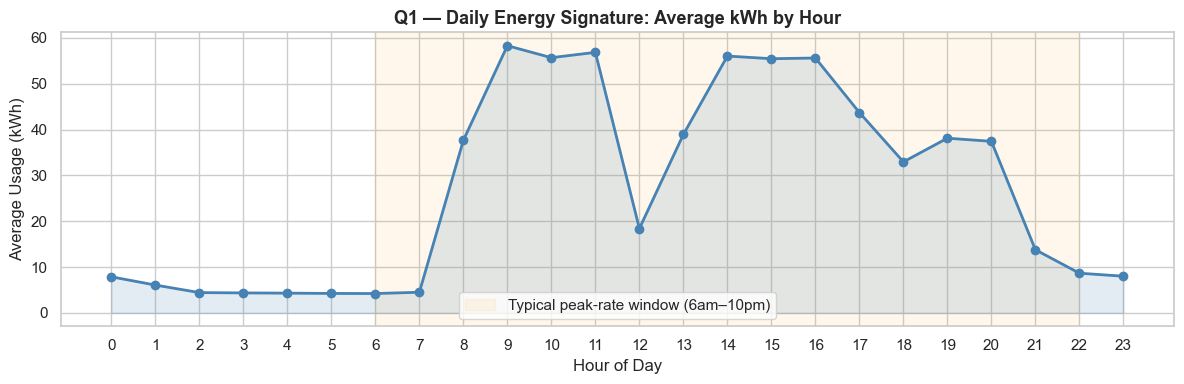

Peak hour    : 9:00  →  58.28 kWh avg
Trough hour  : 6:00  →  4.22 kWh avg
Peak/trough ratio: 13.8x


In [33]:
hourly_avg = df_clean.groupby('hour')['Usage_kWh'].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hourly_avg.index, hourly_avg.values, marker='o', linewidth=2, color='steelblue', markersize=6)
ax.axvspan(6, 22, alpha=0.08, color='orange', label='Typical peak-rate window (6am–10pm)')
ax.fill_between(hourly_avg.index, hourly_avg.values, alpha=0.15, color='steelblue')
ax.set_title('Q1 — Daily Energy Signature: Average kWh by Hour', fontsize=13, fontweight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Average Usage (kWh)')
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()

peak_hour   = hourly_avg.idxmax()
trough_hour = hourly_avg.idxmin()
print(f'Peak hour    : {peak_hour}:00  →  {hourly_avg[peak_hour]:.2f} kWh avg')
print(f'Trough hour  : {trough_hour}:00  →  {hourly_avg[trough_hour]:.2f} kWh avg')
print(f'Peak/trough ratio: {hourly_avg[peak_hour]/hourly_avg[trough_hour]:.1f}x')

### Q2 — Weekday vs. Weekend Consumption
*How different is the energy floor on weekends?*

C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\852049757.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hourly_week = df_clean.groupby(['WeekStatus', 'hour'])['Usage_kWh'].mean().reset_index()


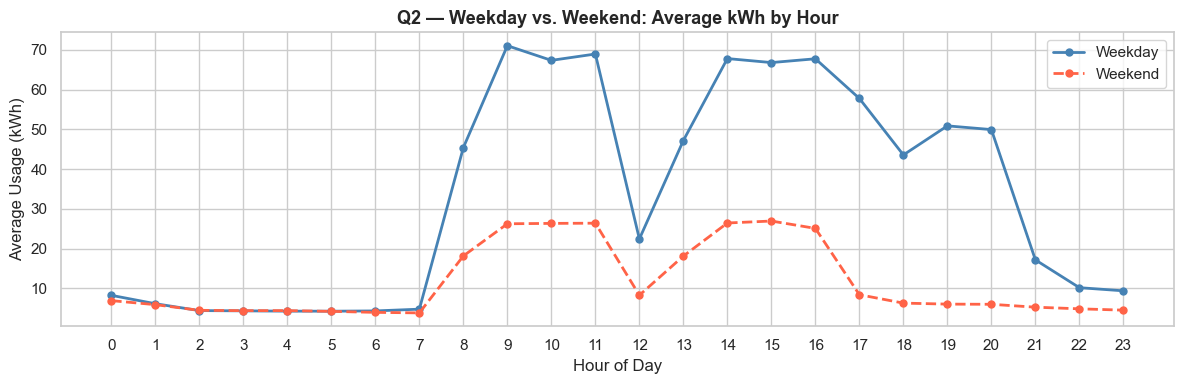

Weekday daily avg            : 33.52 kWh
Weekend daily avg            : 11.73 kWh
Weekend as % of weekday      : 35.0%  ← this is the baseline floor


In [34]:
hourly_week = df_clean.groupby(['WeekStatus', 'hour'])['Usage_kWh'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 4))
for status, color, ls in [('Weekday','steelblue','-'), ('Weekend','tomato','--')]:
    subset = hourly_week[hourly_week['WeekStatus'] == status]
    ax.plot(subset['hour'], subset['Usage_kWh'], marker='o', linewidth=2,
            color=color, linestyle=ls, markersize=5, label=status)

ax.set_title('Q2 — Weekday vs. Weekend: Average kWh by Hour', fontsize=13, fontweight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Average Usage (kWh)')
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()

wd_avg = hourly_week[hourly_week['WeekStatus']=='Weekday']['Usage_kWh'].mean()
we_avg = hourly_week[hourly_week['WeekStatus']=='Weekend']['Usage_kWh'].mean()
print(f'Weekday daily avg            : {wd_avg:.2f} kWh')
print(f'Weekend daily avg            : {we_avg:.2f} kWh')
print(f'Weekend as % of weekday      : {we_avg/wd_avg*100:.1f}%  ← this is the baseline floor')

### Q3 — Day × Hour Consumption Heatmap
*Is there a consistent weekly rhythm, or does it shift around?*

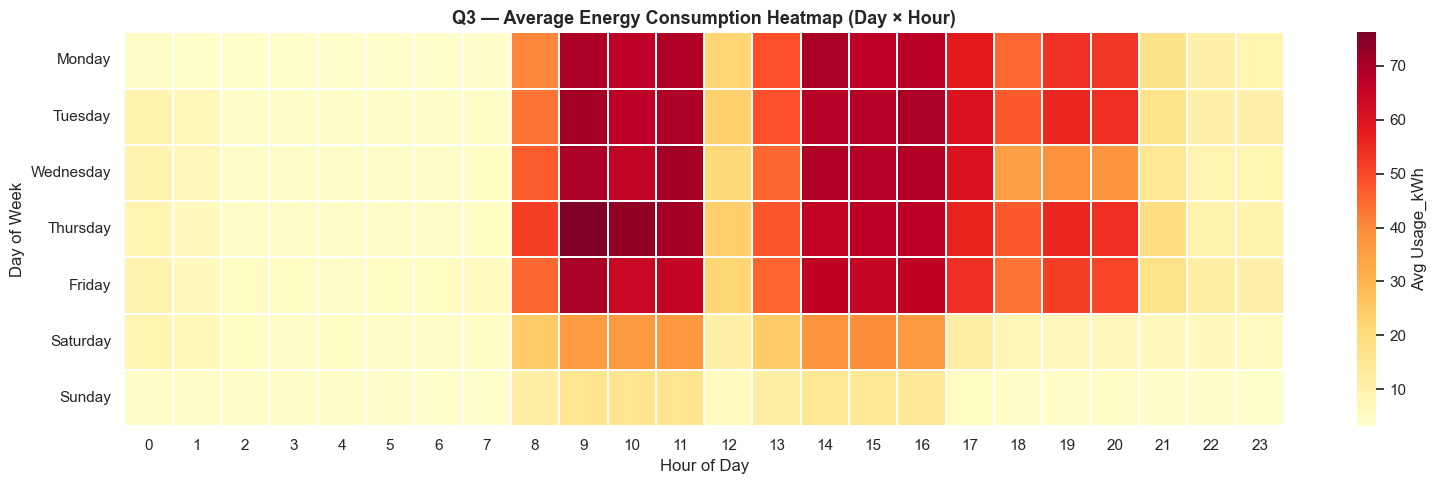

Hotspot: Thursday at 9:00 → 76.19 kWh avg


In [35]:
pivot = df_clean.pivot_table(values='Usage_kWh', index='Day_of_week', columns='hour', aggfunc='mean')

fig, ax = plt.subplots(figsize=(16, 5))
sns.heatmap(pivot, cmap='YlOrRd', linewidths=0.3, linecolor='white',
            annot=False, ax=ax, cbar_kws={'label': 'Avg Usage_kWh'})
ax.set_title('Q3 — Average Energy Consumption Heatmap (Day × Hour)', fontsize=13, fontweight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Day of Week')
plt.tight_layout()
plt.show()

hotspot = pivot.stack().idxmax()
print(f'Hotspot: {hotspot[0]} at {hotspot[1]}:00 → {pivot.stack().max():.2f} kWh avg')

### Q4 — Pareto: Top 10% of Intervals Drive What % of Total Energy?
*You don't need to optimise everything — just the top 3,504 windows*

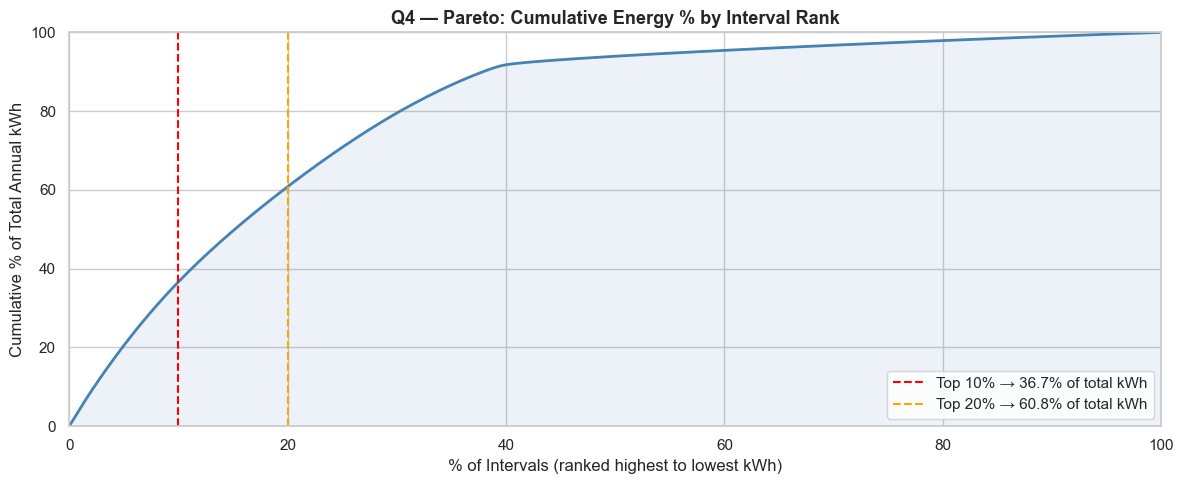

Top 10% of intervals (3,504 windows) → 36.7% of total annual kWh
Top 20% of intervals (7,008 windows) → 60.8% of total annual kWh
Total annual consumption: 956,931 kWh


In [36]:
df_sorted = df_clean.sort_values('Usage_kWh', ascending=False).reset_index(drop=True)
df_sorted['cumulative_pct'] = df_sorted['Usage_kWh'].cumsum() / df_sorted['Usage_kWh'].sum() * 100
df_sorted['interval_pct']   = (df_sorted.index + 1) / len(df_sorted) * 100

top10_share = df_sorted[df_sorted['interval_pct'] <= 10]['Usage_kWh'].sum() / df_sorted['Usage_kWh'].sum() * 100
top20_share = df_sorted[df_sorted['interval_pct'] <= 20]['Usage_kWh'].sum() / df_sorted['Usage_kWh'].sum() * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_sorted['interval_pct'], df_sorted['cumulative_pct'], color='steelblue', linewidth=2)
ax.axvline(10, color='red', linestyle='--', linewidth=1.5, label=f'Top 10% → {top10_share:.1f}% of total kWh')
ax.axvline(20, color='orange', linestyle='--', linewidth=1.5, label=f'Top 20% → {top20_share:.1f}% of total kWh')
ax.fill_between(df_sorted['interval_pct'], df_sorted['cumulative_pct'], alpha=0.1, color='steelblue')
ax.set_title('Q4 — Pareto: Cumulative Energy % by Interval Rank', fontsize=13, fontweight='bold')
ax.set_xlabel('% of Intervals (ranked highest to lowest kWh)')
ax.set_ylabel('Cumulative % of Total Annual kWh')
ax.legend()
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

print(f'Top 10% of intervals ({int(len(df_sorted)*0.1):,} windows) → {top10_share:.1f}% of total annual kWh')
print(f'Top 20% of intervals ({int(len(df_sorted)*0.2):,} windows) → {top20_share:.1f}% of total annual kWh')
print(f'Total annual consumption: {df_sorted["Usage_kWh"].sum():,.0f} kWh')

### Q5 — Energy Distribution by Load Type
*What percentage of total annual kWh comes from each operating state?*

Load Type Summary:
                 Total_kWh  kWh_%  Interval_Count  Interval_%
Load_Type                                                    
Light_Load    155664.32375  16.27           18072       51.58
Medium_Load   371552.95750  38.83            9696       27.67
Maximum_Load  429714.14875  44.91            7272       20.75


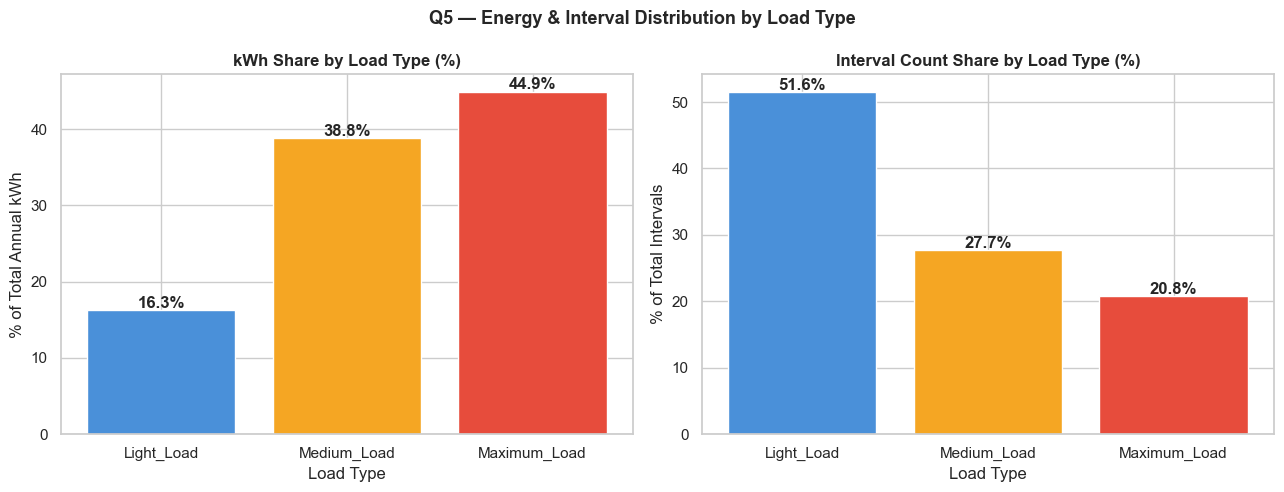


Light_Load accounts for 16.3% of total annual kWh (155,664 kWh)
This is the cost of being switched on but not fully productive.


In [37]:
load_kwh   = df_clean.groupby('Load_Type', observed=True)['Usage_kWh'].sum()
load_pct   = (load_kwh / load_kwh.sum() * 100).round(2)
load_count = df_clean['Load_Type'].value_counts()

summary = pd.DataFrame({
    'Total_kWh': load_kwh,
    'kWh_%': load_pct,
    'Interval_Count': load_count,
    'Interval_%': (load_count / len(df_clean) * 100).round(2)
})
print('Load Type Summary:')
print(summary.to_string())

colors = ['#4a90d9', '#f5a623', '#e74c3c']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(load_pct.index.astype(str), load_pct.values, color=colors, edgecolor='white')
axes[0].set_title('kWh Share by Load Type (%)', fontweight='bold')
axes[0].set_ylabel('% of Total Annual kWh')
axes[0].set_xlabel('Load Type')
for i, v in enumerate(load_pct.values):
    axes[0].text(i, v + 0.3, f'{v:.1f}%', ha='center', fontweight='bold')

interval_pct = (load_count / len(df_clean) * 100)
axes[1].bar(interval_pct.index.astype(str), interval_pct.values, color=colors, edgecolor='white')
axes[1].set_title('Interval Count Share by Load Type (%)', fontweight='bold')
axes[1].set_ylabel('% of Total Intervals')
axes[1].set_xlabel('Load Type')
for i, v in enumerate(interval_pct.values):
    axes[1].text(i, v + 0.3, f'{v:.1f}%', ha='center', fontweight='bold')

plt.suptitle('Q5 — Energy & Interval Distribution by Load Type', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

light_kwh_pct = load_pct.get('Light_Load', 0)
light_kwh_abs = load_kwh.get('Light_Load', 0)
print(f'\nLight_Load accounts for {light_kwh_pct:.1f}% of total annual kWh ({light_kwh_abs:,.0f} kWh)')
print('This is the cost of being switched on but not fully productive.')

---
## 9. Phase 3 — Efficiency Analysis
> **Core question:** How well is the plant converting electricity into useful work?

Key concept: a power factor below 0.85 triggers utility penalty charges. Every interval below that threshold is money paid for reactive energy that did no productive work.

### Q6 — Power Factor Distribution
*How much of the distribution sits below the 0.85 penalty threshold?*

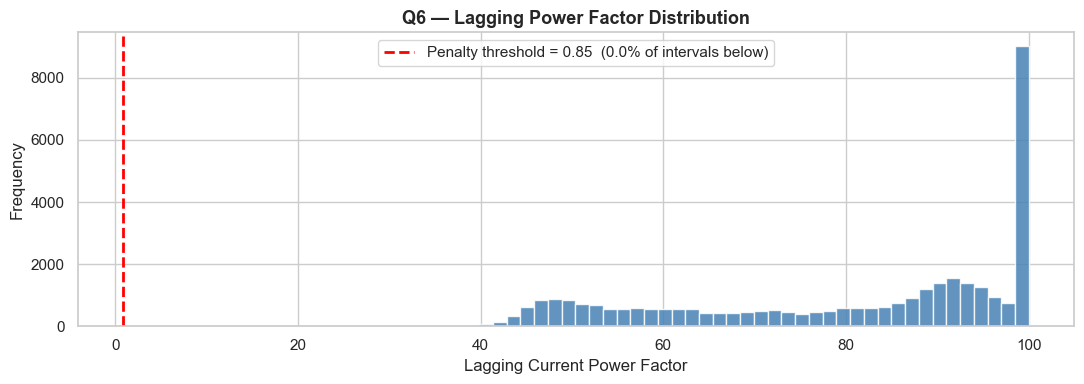

Intervals below PF 0.85: 0 of 35,040 (0.0%)
Mean PF  : 80.578
Median PF: 87.960
Min PF   : 9.766


In [38]:
pf_col    = 'Lagging_Current_Power_Factor'
THRESHOLD = 0.85

below     = (df_clean[pf_col] < THRESHOLD).sum()
below_pct = below / len(df_clean) * 100

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(df_clean[pf_col], bins=60, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(THRESHOLD, color='red', linewidth=2, linestyle='--',
           label=f'Penalty threshold = {THRESHOLD}  ({below_pct:.1f}% of intervals below)')
ax.set_title('Q6 — Lagging Power Factor Distribution', fontsize=13, fontweight='bold')
ax.set_xlabel('Lagging Current Power Factor')
ax.set_ylabel('Frequency')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Intervals below PF {THRESHOLD}: {below:,} of {len(df_clean):,} ({below_pct:.1f}%)')
print(f'Mean PF  : {df_clean[pf_col].mean():.3f}')
print(f'Median PF: {df_clean[pf_col].median():.3f}')
print(f'Min PF   : {df_clean[pf_col].min():.3f}')

### Q7 — When Does Power Factor Drop Lowest?
*Is the pattern time-driven (systematic) or random?*

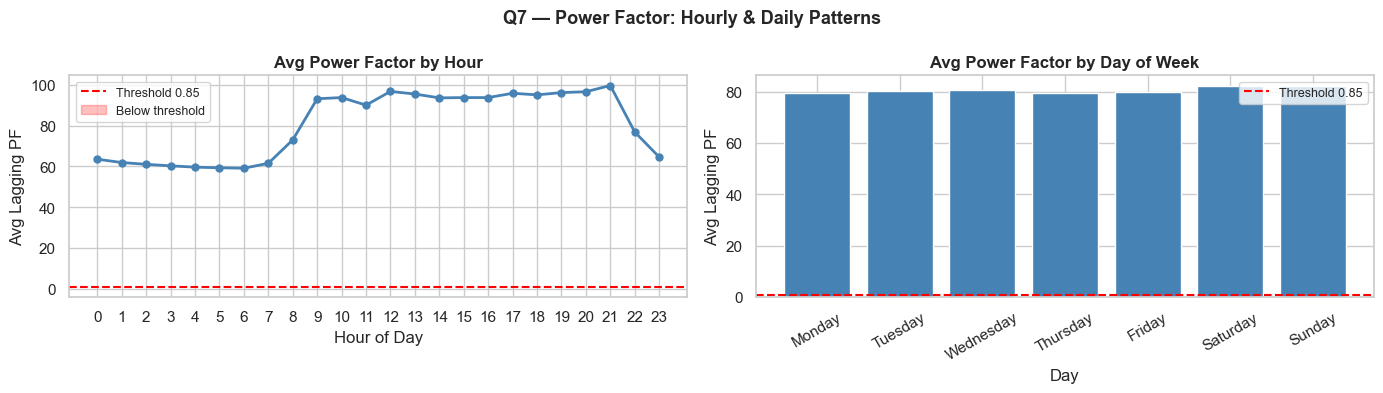

Worst hour for PF: 6:00  → avg PF = 59.057
Worst day for PF : Thursday   → avg PF = 79.562


In [39]:
pf_by_hour = df_clean.groupby('hour')[pf_col].mean()
pf_by_day  = df_clean.groupby('Day_of_week', observed=True)[pf_col].mean().reindex(day_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(pf_by_hour.index, pf_by_hour.values, marker='o', linewidth=2, color='steelblue', markersize=5)
axes[0].axhline(THRESHOLD, color='red', linestyle='--', linewidth=1.5, label=f'Threshold {THRESHOLD}')
axes[0].fill_between(pf_by_hour.index, pf_by_hour.values, THRESHOLD,
                      where=(pf_by_hour.values < THRESHOLD),
                      alpha=0.25, color='red', label='Below threshold')
axes[0].set_title('Avg Power Factor by Hour', fontweight='bold')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Avg Lagging PF')
axes[0].set_xticks(range(0, 24))
axes[0].legend(fontsize=9)

bar_colors = ['tomato' if v < THRESHOLD else 'steelblue' for v in pf_by_day.values]
axes[1].bar(pf_by_day.index.astype(str), pf_by_day.values, color=bar_colors, edgecolor='white')
axes[1].axhline(THRESHOLD, color='red', linestyle='--', linewidth=1.5, label=f'Threshold {THRESHOLD}')
axes[1].set_title('Avg Power Factor by Day of Week', fontweight='bold')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Avg Lagging PF')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(fontsize=9)

plt.suptitle('Q7 — Power Factor: Hourly & Daily Patterns', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

worst_hour = pf_by_hour.idxmin()
worst_day  = pf_by_day.idxmin()
print(f'Worst hour for PF: {worst_hour}:00  → avg PF = {pf_by_hour[worst_hour]:.3f}')
print(f'Worst day for PF : {worst_day}   → avg PF = {pf_by_day[worst_day]:.3f}')

### Q8 — Reactive Power vs. Total Consumption
*Where are the outliers — high reactive, low useful output?*

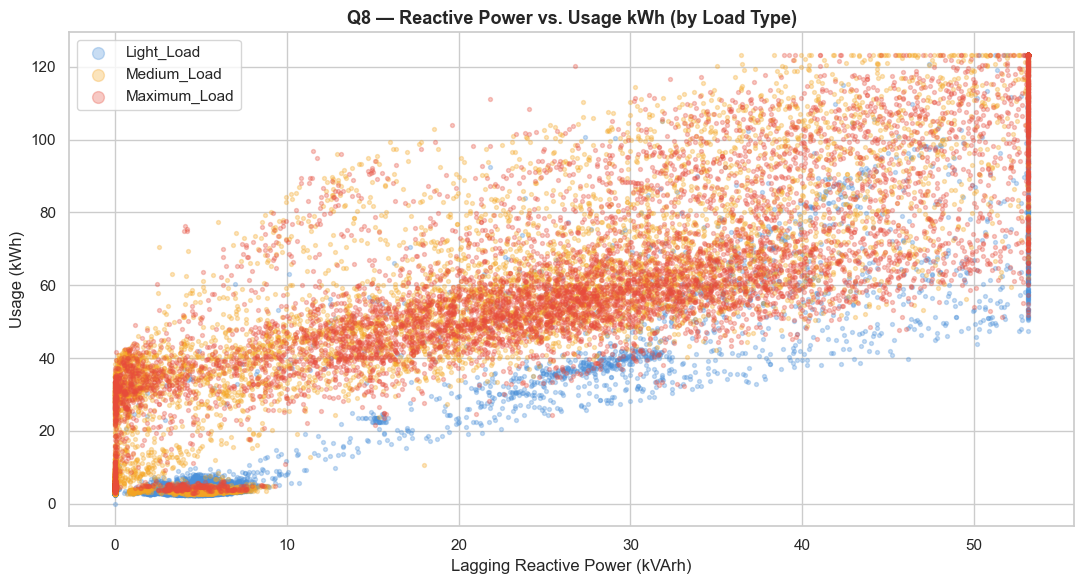

High reactive + low kWh anomalies: 0 intervals (0.0%)
These intervals draw reactive power without productive consumption.


In [40]:
rp_col = 'Lagging_Current_Reactive_Power_kVarh'
load_palette = {'Light_Load': '#4a90d9', 'Medium_Load': '#f5a623', 'Maximum_Load': '#e74c3c'}

fig, ax = plt.subplots(figsize=(11, 6))
for lt in load_order:
    subset = df_clean[df_clean['Load_Type'] == lt]
    ax.scatter(subset[rp_col], subset['Usage_kWh'],
               alpha=0.3, s=8, color=load_palette[lt], label=lt)

ax.set_title('Q8 — Reactive Power vs. Usage kWh (by Load Type)', fontsize=13, fontweight='bold')
ax.set_xlabel('Lagging Reactive Power (kVArh)')
ax.set_ylabel('Usage (kWh)')
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

rp_75  = df_clean[rp_col].quantile(0.75)
kwh_25 = df_clean['Usage_kWh'].quantile(0.25)
anomalous = df_clean[(df_clean[rp_col] > rp_75) & (df_clean['Usage_kWh'] < kwh_25)]
print(f'High reactive + low kWh anomalies: {len(anomalous):,} intervals ({len(anomalous)/len(df_clean)*100:.1f}%)')
print('These intervals draw reactive power without productive consumption.')

### Q9 — What Fraction of Apparent Power Is Reactive?
*Quantify the reactive penalty load across all operating hours*

In [41]:
# Apparent power: S = P / PF
df_clean['Apparent_kVAh'] = df_clean.apply(
    lambda r: r['Usage_kWh'] / r[pf_col] if r[pf_col] > 0 else np.nan, axis=1
)

total_active   = df_clean['Usage_kWh'].sum()
total_reactive = df_clean[rp_col].sum()
total_apparent = df_clean['Apparent_kVAh'].sum()
reactive_pct   = total_reactive / total_apparent * 100

print('=== Reactive Power Summary ===')
print(f'Total active energy   : {total_active:>12,.0f} kWh')
print(f'Total reactive energy  : {total_reactive:>12,.0f} kVArh')
print(f'Total apparent energy  : {total_apparent:>12,.0f} kVAh')
print(f'Reactive fraction      : {reactive_pct:.1f}%  ← % of apparent power that is non-productive')

# Penalty cost estimate
PENALTY_RATE   = 0.03  # AED per kVArh — adjust to actual tariff
penalisable    = df_clean.loc[df_clean[pf_col] < THRESHOLD, rp_col].sum()
penalty_cost   = penalisable * PENALTY_RATE

print(f'\nPenalisable kVArh (PF < {THRESHOLD}): {penalisable:,.0f}')
print(f'Estimated penalty @ AED {PENALTY_RATE}/kVArh : AED {penalty_cost:,.0f}')
print('(Adjust PENALTY_RATE to match actual ADDC tariff for EMSTEEL context)')

df_clean.drop(columns=['Apparent_kVAh'], inplace=True, errors='ignore')

=== Reactive Power Summary ===
Total active energy   :      956,931 kWh
Total reactive energy  :      448,184 kVArh
Total apparent energy  :       10,848 kVAh
Reactive fraction      : 4131.6%  ← % of apparent power that is non-productive

Penalisable kVArh (PF < 0.85): 0
Estimated penalty @ AED 0.03/kVArh : AED 0
(Adjust PENALTY_RATE to match actual ADDC tariff for EMSTEEL context)


### Q10 — Leading vs. Lagging Reactive Power
*Is there enough natural compensation, or does the plant need capacitor banks?*

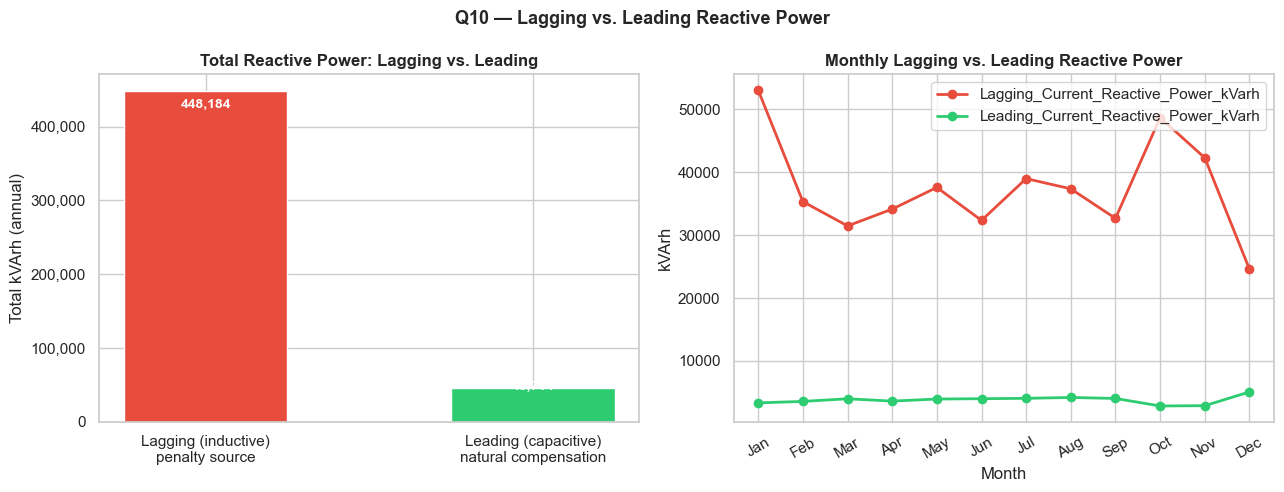

Total lagging reactive  :      448,184 kVArh
Total leading reactive  :       45,714 kVArh
Leading compensates     : 10.2% of lagging
Net uncompensated lag   :      402,470 kVArh

Finding: Leading reactive power is negligible relative to lagging.
No meaningful natural compensation — supports the case for capacitor bank installation.


In [42]:
lag_col  = 'Lagging_Current_Reactive_Power_kVarh'
lead_col = 'Leading_Current_Reactive_Power_kVarh'

total_lag  = df_clean[lag_col].sum()
total_lead = df_clean[lead_col].sum()
compensation_pct = total_lead / total_lag * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(['Lagging (inductive)\npenalty source', 'Leading (capacitive)\nnatural compensation'],
            [total_lag, total_lead],
            color=['#e74c3c', '#2ecc71'], edgecolor='white', width=0.5)
axes[0].set_title('Total Reactive Power: Lagging vs. Leading', fontweight='bold')
axes[0].set_ylabel('Total kVArh (annual)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
for i, v in enumerate([total_lag, total_lead]):
    axes[0].text(i, v * 0.95, f'{v:,.0f}', ha='center', color='white', fontweight='bold', fontsize=10)

monthly_rp = df_clean.groupby('month')[[lag_col, lead_col]].sum()
monthly_rp.plot(kind='line', marker='o', ax=axes[1],
                color=['#e74c3c', '#2ecc71'], linewidth=2)
axes[1].set_title('Monthly Lagging vs. Leading Reactive Power', fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('kVArh')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=30)

plt.suptitle('Q10 — Lagging vs. Leading Reactive Power', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Total lagging reactive  : {total_lag:>12,.0f} kVArh')
print(f'Total leading reactive  : {total_lead:>12,.0f} kVArh')
print(f'Leading compensates     : {compensation_pct:.1f}% of lagging')
print(f'Net uncompensated lag   : {total_lag - total_lead:>12,.0f} kVArh')
if compensation_pct < 20:
    print('\nFinding: Leading reactive power is negligible relative to lagging.')
    print('No meaningful natural compensation — supports the case for capacitor bank installation.')

---
## 10. Phase Summary — Business Translation

| Finding | Metric | Business Implication |
|---|---|---|
| Peak consumption hour | Q1 output | Is it inside the peak-rate tariff window? |
| Weekend floor | Q2 output | Baseline draw from standby equipment |
| Heatmap hot spots | Q3 | Consistent = schedule-driven = controllable |
| Top 10% intervals | Q4 output | Focus optimisation here only |
| Light_Load kWh share | Q5 output | Cost of being on but not productive |
| % intervals below PF 0.85 | Q6 output | Fraction of operating time incurring penalties |
| Worst PF hour/day | Q7 output | Systematic pattern → systematic fix |
| High reactive + low kWh | Q8 anomalies | Specific intervals to investigate |
| Reactive fraction | Q9 output | % of electricity spend that is a penalty |
| Leading vs. lagging gap | Q10 output | Case for capacitor bank investment |

---
## 11. Phase 4 — CO₂ as a Production Signal
> **Core question:** Are we producing when we are consuming?

No production volume column exists. CO₂ is the closest proxy for how hard the plant was working. Every analysis here asks: does the energy spend correspond to a plant that was actually producing?

### Q11 — How Tightly Does CO₂ Track Energy Consumption?
*Where the two diverge is where the interesting story lives*

C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\2850509791.py:25: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
c:\Users\mar-w\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


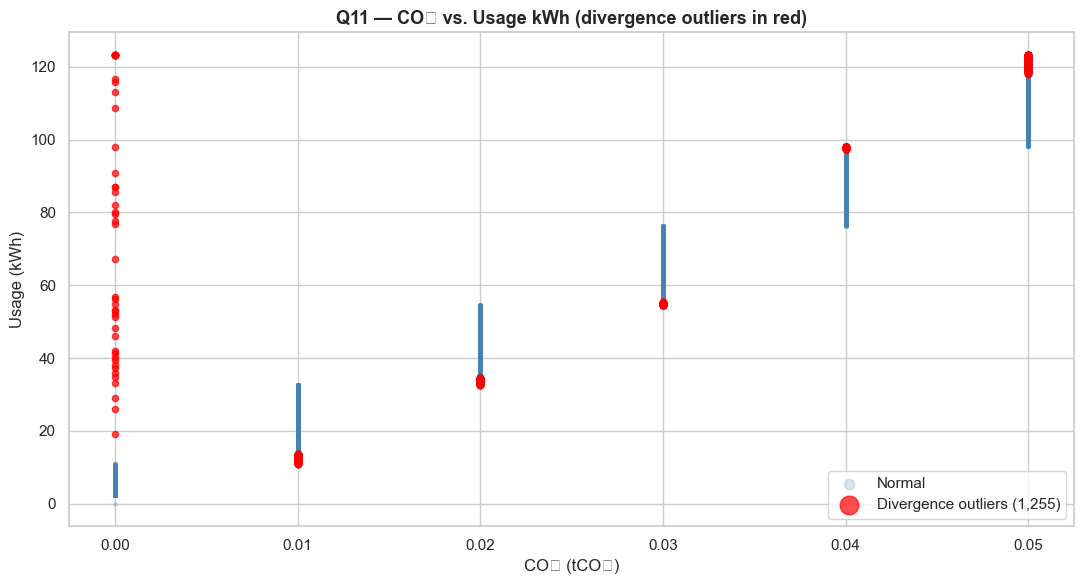

Pearson r (CO₂ vs kWh)       : 0.987
Divergence outliers           : 1,255 (3.6%)
High kWh + low CO₂ intervals  : 0  ← energy spend without production activity


In [43]:
co2_col = "CO2(tCO2)"

# Divergence: residuals from a linear fit
from numpy.polynomial.polynomial import polyfit
mask = df_clean[co2_col].notna() & df_clean["Usage_kWh"].notna()
x = df_clean.loc[mask, co2_col].values
y = df_clean.loc[mask, "Usage_kWh"].values
c0, c1 = polyfit(x, y, 1)
df_clean["co2_kwh_residual"] = df_clean["Usage_kWh"] - (c0 + c1 * df_clean[co2_col])

# Flag divergence outliers: |residual| > 2 std
res_std = df_clean["co2_kwh_residual"].std()
df_clean["divergence"] = df_clean["co2_kwh_residual"].abs() > 2 * res_std

fig, ax = plt.subplots(figsize=(11, 6))
normal  = df_clean[~df_clean["divergence"]]
outlier = df_clean[df_clean["divergence"]]
ax.scatter(normal[co2_col],  normal["Usage_kWh"],  alpha=0.2, s=6,  color="steelblue", label="Normal")
ax.scatter(outlier[co2_col], outlier["Usage_kWh"], alpha=0.7, s=20, color="red",
           label=f"Divergence outliers ({len(outlier):,})")
ax.set_title("Q11 — CO₂ vs. Usage kWh (divergence outliers in red)", fontsize=13, fontweight="bold")
ax.set_xlabel("CO₂ (tCO₂)")
ax.set_ylabel("Usage (kWh)")
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

corr = df_clean[[co2_col, "Usage_kWh"]].corr().iloc[0, 1]
high_kwh_low_co2 = df_clean[
    (df_clean["Usage_kWh"] > df_clean["Usage_kWh"].quantile(0.75)) &
    (df_clean[co2_col]     < df_clean[co2_col].quantile(0.25))
]
print(f"Pearson r (CO₂ vs kWh)       : {corr:.3f}")
print(f"Divergence outliers           : {len(outlier):,} ({len(outlier)/len(df_clean)*100:.1f}%)")
print(f"High kWh + low CO₂ intervals  : {len(high_kwh_low_co2):,}  ← energy spend without production activity")


### Q12 — CO₂ Intensity by Load Type
*Are the three operating states cleanly separated in CO₂ space?*

C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\2773958286.py:13: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
c:\Users\mar-w\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


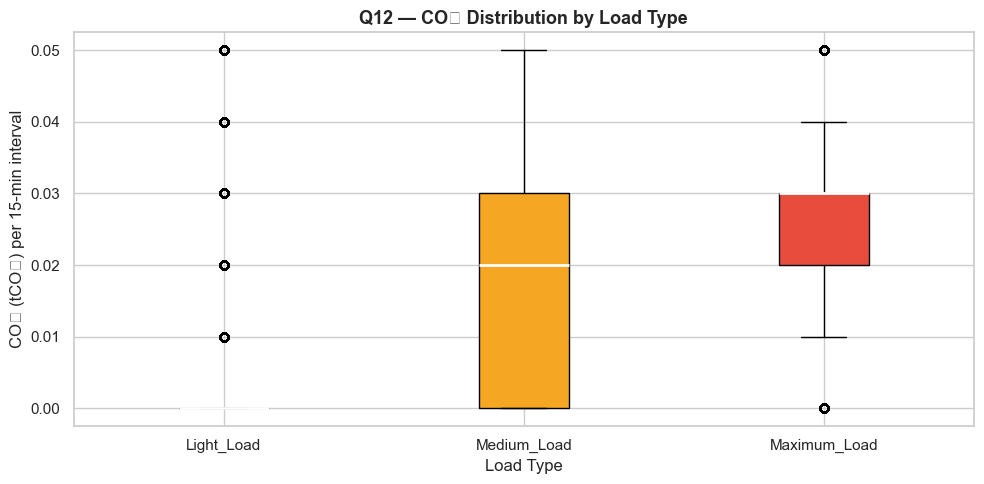

CO₂ stats by Load Type:
                mean  median     std  min   max
Load_Type                                      
Light_Load    0.0025    0.00  0.0086  0.0  0.05
Medium_Load   0.0165    0.02  0.0166  0.0  0.05
Maximum_Load  0.0266    0.03  0.0137  0.0  0.05

Light_Load intervals with CO₂ > 0: 1,731 of 18,072 (9.6%) — something running during idle.


In [44]:
fig, ax = plt.subplots(figsize=(10, 5))
colors_lt = {"Light_Load": "#4a90d9", "Medium_Load": "#f5a623", "Maximum_Load": "#e74c3c"}
data_by_load = [df_clean.loc[df_clean["Load_Type"] == lt, co2_col].dropna().values
                for lt in load_order]
bp = ax.boxplot(data_by_load, patch_artist=True,
                medianprops=dict(color="white", linewidth=2))
for patch, lt in zip(bp["boxes"], load_order):
    patch.set_facecolor(colors_lt[lt])
ax.set_xticklabels(load_order)
ax.set_title("Q12 — CO₂ Distribution by Load Type", fontsize=13, fontweight="bold")
ax.set_xlabel("Load Type")
ax.set_ylabel("CO₂ (tCO₂) per 15-min interval")
plt.tight_layout()
plt.show()

print("CO₂ stats by Load Type:")
print(df_clean.groupby("Load_Type", observed=True)[co2_col]
      .agg(["mean", "median", "std", "min", "max"]).round(4).to_string())

light_co2_nonzero = (df_clean.loc[df_clean["Load_Type"] == "Light_Load", co2_col] > 0).sum()
light_total = (df_clean["Load_Type"] == "Light_Load").sum()
print(f"\nLight_Load intervals with CO₂ > 0: {light_co2_nonzero:,} of {light_total:,}"
      f" ({light_co2_nonzero/light_total*100:.1f}%) — something running during idle.")


### Q13 — CO₂ Heatmap vs. kWh Heatmap
*Misalignment reveals peak energy spend during low-activity windows*

c:\Users\mar-w\anaconda3\Lib\site-packages\seaborn\utils.py:80: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.draw()
C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\3195568473.py:18: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
c:\Users\mar-w\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


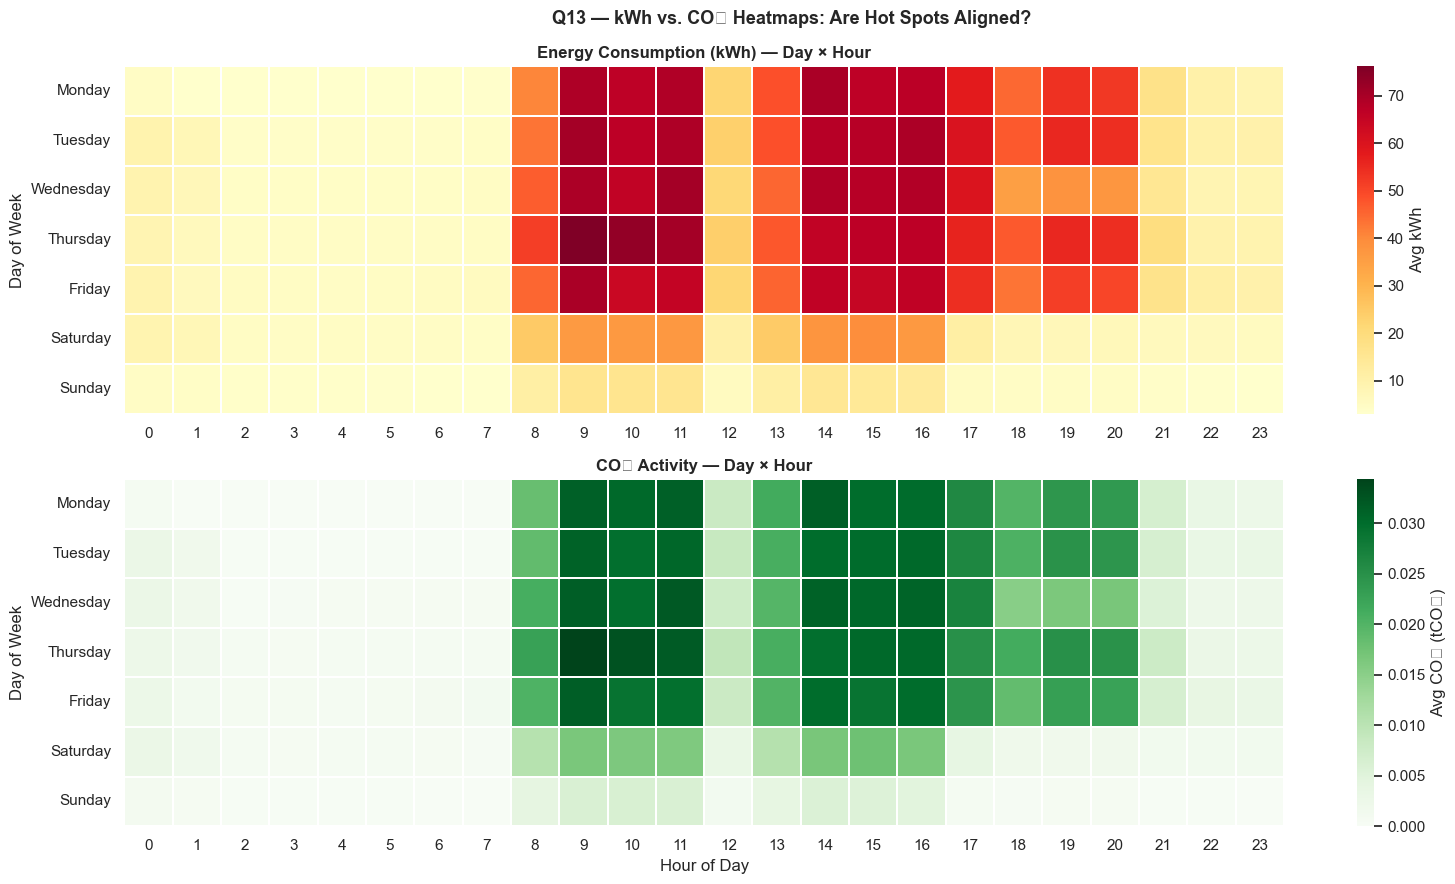

Hours with largest kWh vs CO₂ rank mismatch (top 5):
hour
2    4.0
4    3.0
5    3.0
7    2.0
3    1.5

Large mismatch = high energy spend during low-activity window.


In [45]:
pivot_co2 = df_clean.pivot_table(values=co2_col,     index="Day_of_week", columns="hour", aggfunc="mean")
pivot_kwh = df_clean.pivot_table(values="Usage_kWh", index="Day_of_week", columns="hour", aggfunc="mean")

fig, axes = plt.subplots(2, 1, figsize=(16, 9))
sns.heatmap(pivot_kwh, cmap="YlOrRd", linewidths=0.2, linecolor="white",
            ax=axes[0], cbar_kws={"label": "Avg kWh"})
axes[0].set_title("Energy Consumption (kWh) — Day × Hour", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Day of Week")

sns.heatmap(pivot_co2, cmap="Greens", linewidths=0.2, linecolor="white",
            ax=axes[1], cbar_kws={"label": "Avg CO₂ (tCO₂)"})
axes[1].set_title("CO₂ Activity — Day × Hour", fontweight="bold")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Day of Week")

plt.suptitle("Q13 — kWh vs. CO₂ Heatmaps: Are Hot Spots Aligned?", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Rank mismatch: hours where kWh rank is high but CO₂ rank is low
hourly_kwh_rank = df_clean.groupby("hour")["Usage_kWh"].mean().rank(ascending=False)
hourly_co2_rank = df_clean.groupby("hour")[co2_col].mean().rank(ascending=False)
mismatch = (hourly_kwh_rank - hourly_co2_rank).abs().sort_values(ascending=False)
print("Hours with largest kWh vs CO₂ rank mismatch (top 5):")
print(mismatch.head().to_string())
print("\nLarge mismatch = high energy spend during low-activity window.")


### Q14 — The Cost of Zero-CO₂ Periods
*Energy consumed when there is demonstrably no production activity*

=== Zero-CO₂ Interval Summary ===
Total intervals           : 35,040
Zero-CO₂ intervals        : 20,990 (59.9%)
Zero-CO₂ kWh              : 81,413.5 kWh (8.5% of annual total)
Estimated cost @ AED 0.23 : AED 18,725

This is not the cost of making steel — it is the cost of the plant being switched on.

Zero-CO₂ kWh by Load Type:
              count      sum
Load_Type                   
Light_Load    16341  56677.8
Medium_Load    3979  20057.0
Maximum_Load    670   4678.7


C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\2900083619.py:28: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
c:\Users\mar-w\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


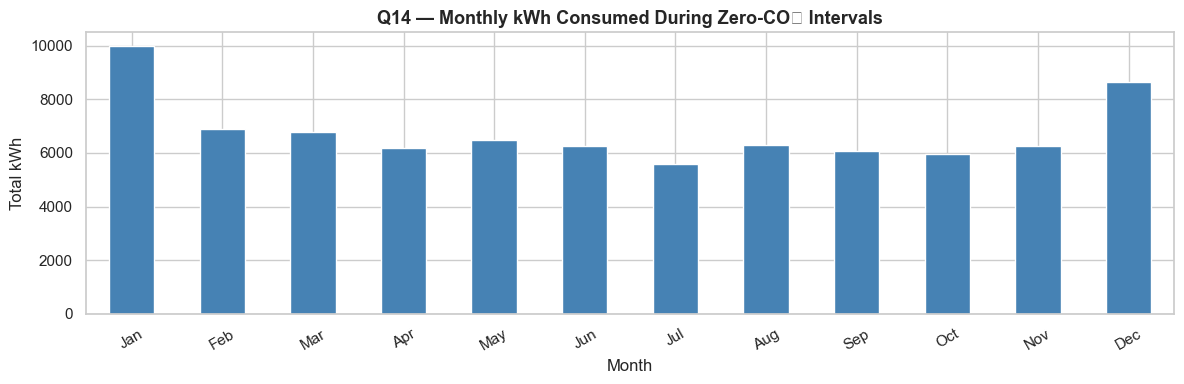

In [46]:
zero_co2  = df_clean[df_clean[co2_col] == 0]
zero_kwh  = zero_co2["Usage_kWh"].sum()
zero_pct  = zero_kwh / df_clean["Usage_kWh"].sum() * 100
OFFPEAK_RATE = 0.23  # AED per kWh — adjust to actual tariff
cost_est  = zero_kwh * OFFPEAK_RATE

print("=== Zero-CO₂ Interval Summary ===")
print(f"Total intervals           : {len(df_clean):,}")
print(f"Zero-CO₂ intervals        : {len(zero_co2):,} ({len(zero_co2)/len(df_clean)*100:.1f}%)")
print(f"Zero-CO₂ kWh              : {zero_kwh:,.1f} kWh ({zero_pct:.1f}% of annual total)")
print(f"Estimated cost @ AED {OFFPEAK_RATE} : AED {cost_est:,.0f}")
print("\nThis is not the cost of making steel — it is the cost of the plant being switched on.")

print("\nZero-CO₂ kWh by Load Type:")
print(zero_co2.groupby("Load_Type", observed=True)["Usage_kWh"]
      .agg(["count", "sum"]).round(1).to_string())

fig, ax = plt.subplots(figsize=(12, 4))
zero_co2.groupby("month")["Usage_kWh"].sum().plot(
    kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_title("Q14 — Monthly kWh Consumed During Zero-CO₂ Intervals",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Total kWh")
ax.set_xticklabels(
    ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"],
    rotation=30)
plt.tight_layout()
plt.show()


---
## 12. Phase 5 — Load Type Deep Dive
> **Core question:** What characterises each load state, and what does each state cost?

Load_Type is the most operationally meaningful variable. This phase uses it as a lens through which every other variable is re-examined.

### Q15 — Total Energy Cost Distributed Across Load Types
*Quantify the efficiency gap by name*

Efficiency ratio = kWh% / Interval%
  < 1 → energy-light relative to frequency
  > 1 → energy-dense relative to frequency
              Total_kWh  kWh_%  Intervals  Interval_%  Efficiency_ratio
Load_Type                                                              
Light_Load     155664.0  16.27      18072       51.58              0.32
Medium_Load    371553.0  38.83       9696       27.67              1.40
Maximum_Load   429714.0  44.91       7272       20.75              2.16


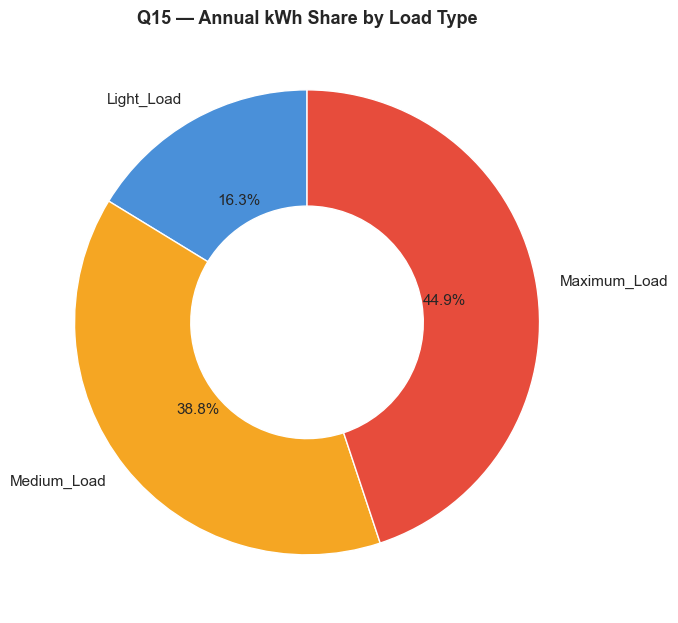

In [47]:
load_kwh      = df_clean.groupby("Load_Type", observed=True)["Usage_kWh"].sum()
load_pct_q15  = load_kwh / load_kwh.sum() * 100
load_count    = df_clean["Load_Type"].value_counts().reindex(load_order)
interval_pct  = load_count / len(df_clean) * 100
eff_ratio     = (load_pct_q15 / interval_pct).round(2)

summary_q15 = pd.DataFrame({
    "Total_kWh":       load_kwh.round(0),
    "kWh_%":           load_pct_q15.round(2),
    "Intervals":       load_count,
    "Interval_%":      interval_pct.round(2),
    "Efficiency_ratio": eff_ratio
})
print("Efficiency ratio = kWh% / Interval%")
print("  < 1 → energy-light relative to frequency")
print("  > 1 → energy-dense relative to frequency")
print(summary_q15.to_string())

# Donut chart
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(load_kwh.values,
       labels=load_kwh.index.astype(str),
       autopct="%1.1f%%",
       colors=["#4a90d9", "#f5a623", "#e74c3c"],
       wedgeprops=dict(width=0.5),
       startangle=90,
       textprops={"fontsize": 11})
ax.set_title("Q15 — Annual kWh Share by Load Type", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


### Q16 — Typical Interval Profile per Load Type
*High within-group variance in Light Load = classification boundary is fuzzy*

Summary statistics by Load Type:
             Usage_kWh                 Lagging_Current_Reactive_Power_kVarh                Leading_Current_Reactive_Power_kVarh               CO2(tCO2)               Lagging_Current_Power_Factor                 Leading_Current_Power_Factor              
                  mean  median     std                                 mean median     std                                 mean median    std      mean median    std                         mean  median     std                         mean median    std
Load_Type                                                                                                                                                                                                                                                    
Light_Load       8.614   3.310  17.821                                6.801   4.46  10.688                                1.021   0.00  2.049     0.003   0.00  0.009                       69.680  66.270  1

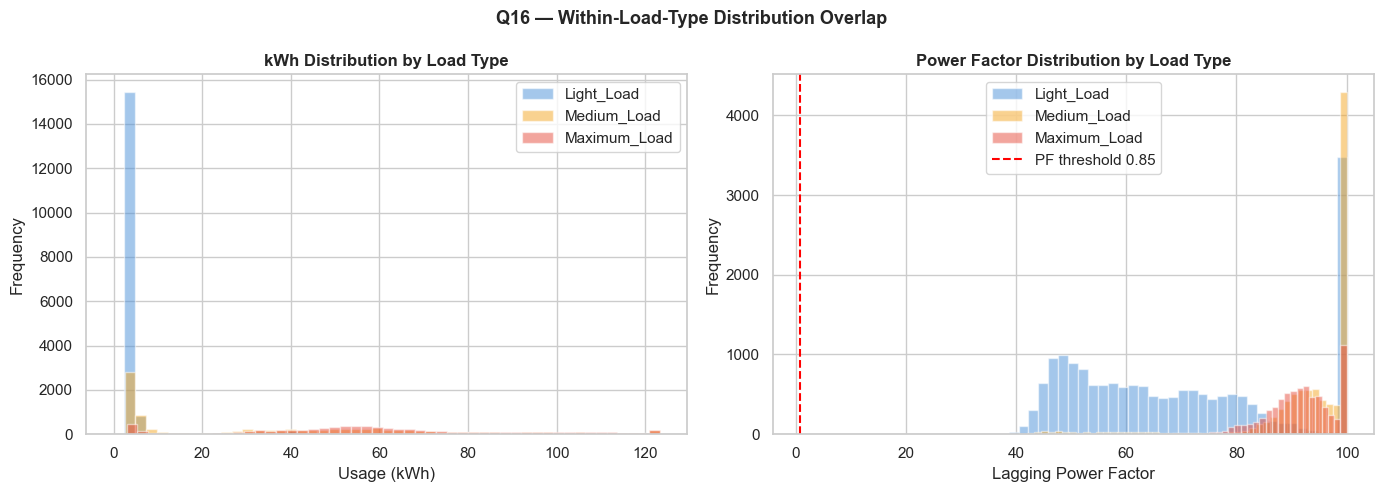

In [48]:
num_cols_q16 = [
    "Usage_kWh", "Lagging_Current_Reactive_Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh", "CO2(tCO2)",
    "Lagging_Current_Power_Factor", "Leading_Current_Power_Factor"
]
stats_q16 = df_clean.groupby("Load_Type", observed=True)[num_cols_q16]\
                    .agg(["mean", "median", "std"])
print("Summary statistics by Load Type:")
print(stats_q16.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_lt = {"Light_Load": "#4a90d9", "Medium_Load": "#f5a623", "Maximum_Load": "#e74c3c"}
for lt in load_order:
    subset = df_clean[df_clean["Load_Type"] == lt]
    axes[0].hist(subset["Usage_kWh"], bins=50, alpha=0.5,
                 color=colors_lt[lt], label=lt, edgecolor="white")
    axes[1].hist(subset["Lagging_Current_Power_Factor"], bins=50, alpha=0.5,
                 color=colors_lt[lt], label=lt, edgecolor="white")

axes[0].set_title("kWh Distribution by Load Type", fontweight="bold")
axes[0].set_xlabel("Usage (kWh)")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].axvline(0.85, color="red", linestyle="--", linewidth=1.5, label="PF threshold 0.85")
axes[1].set_title("Power Factor Distribution by Load Type", fontweight="bold")
axes[1].set_xlabel("Lagging Power Factor")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.suptitle("Q16 — Within-Load-Type Distribution Overlap", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


### Q17 — How Long Do Load State Periods Typically Last?
*Recurring extended Light Load runs during weekday hours = systematic idle periods*

Run duration stats (minutes) by Load Type:
              count   mean  median   max
Load_Type                               
Light_Load      304  891.7   600.0  7800
Medium_Load     909  160.0    60.0   360
Maximum_Load    701  155.6   120.0   240


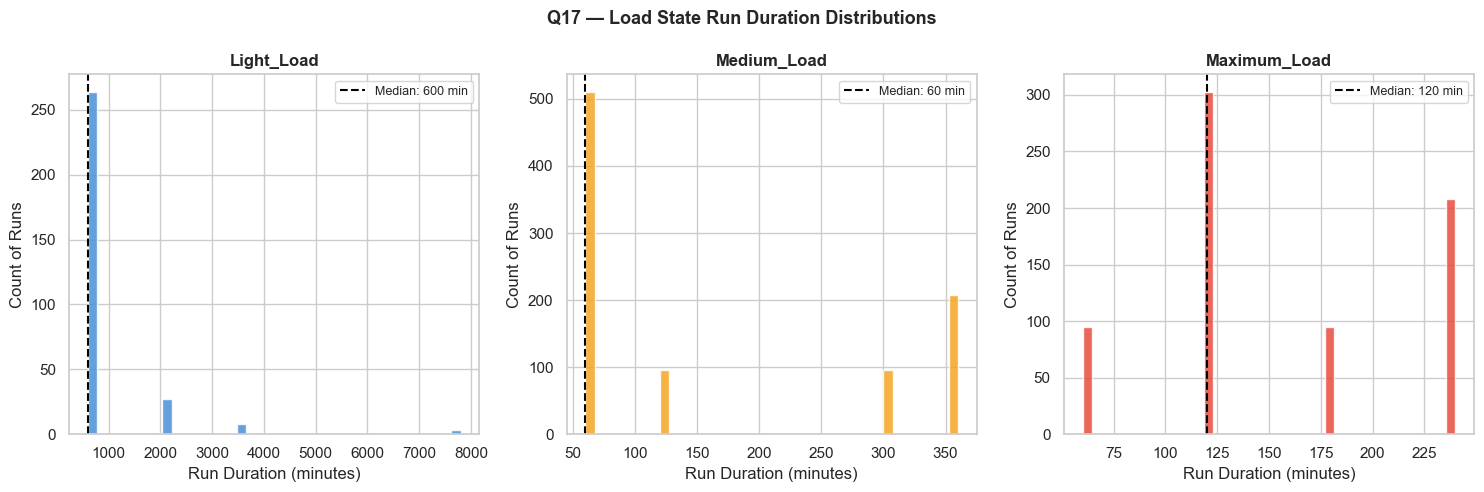


Extended Light Load runs (≥2 hr) on weekday 7am–7pm:
  Distinct runs : 249
  Total kWh     : 73,092 kWh


In [49]:
# Identify consecutive runs of the same Load_Type
df_clean["load_run_id"] = (
    df_clean["Load_Type"] != df_clean["Load_Type"].shift()
).cumsum()

run_lengths = (
    df_clean.groupby(["load_run_id", "Load_Type"], observed=True)
            .size()
            .reset_index(name="intervals")
)
run_lengths["duration_minutes"] = run_lengths["intervals"] * 15

print("Run duration stats (minutes) by Load Type:")
print(run_lengths.groupby("Load_Type", observed=True)["duration_minutes"]
      .agg(["count", "mean", "median", "max"]).round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors_lt = {"Light_Load": "#4a90d9", "Medium_Load": "#f5a623", "Maximum_Load": "#e74c3c"}
for ax, lt in zip(axes, load_order):
    durations = run_lengths.loc[run_lengths["Load_Type"] == lt, "duration_minutes"]
    ax.hist(durations, bins=40, color=colors_lt[lt], edgecolor="white", alpha=0.85)
    ax.axvline(durations.median(), color="black", linestyle="--", linewidth=1.5,
               label=f"Median: {durations.median():.0f} min")
    ax.set_title(lt, fontweight="bold")
    ax.set_xlabel("Run Duration (minutes)")
    ax.set_ylabel("Count of Runs")
    ax.legend(fontsize=9)

plt.suptitle("Q17 — Load State Run Duration Distributions", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Flag extended Light Load on weekday business hours
df_run = df_clean.merge(
    run_lengths[["load_run_id", "duration_minutes"]], on="load_run_id", how="left"
)
long_light = df_run[
    (df_run["Load_Type"] == "Light_Load") &
    (df_run["WeekStatus"] == "Weekday") &
    (df_run["duration_minutes"] >= 120) &
    (df_run["hour"].between(7, 19))
]
print(f"\nExtended Light Load runs (≥2 hr) on weekday 7am–7pm:")
print(f"  Distinct runs : {long_light['load_run_id'].nunique()}")
print(f"  Total kWh     : {long_light['Usage_kWh'].sum():,.0f} kWh")


### Q18 — What Time of Day Does Each Load Type Predominate?
*The reverse-engineered shift schedule*

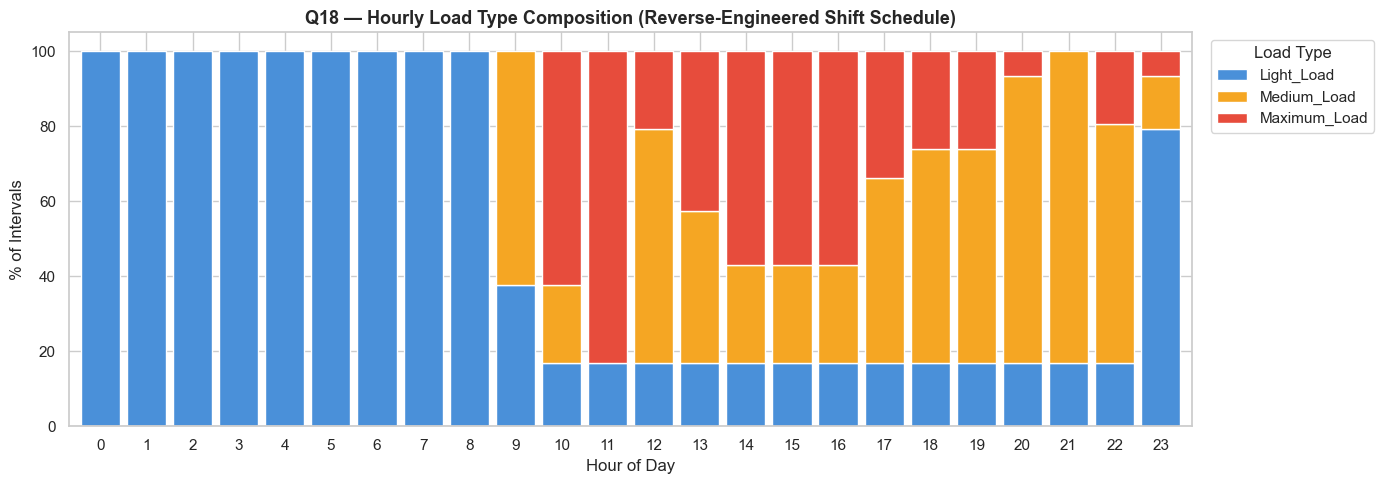

Hours where Maximum_Load dominates: [10, 11, 13, 14, 15, 16]
These are the production shift windows visible purely from energy data.


In [50]:
hourly_load = (
    df_clean.groupby(["hour", "Load_Type"], observed=True)
            .size()
            .reset_index(name="count")
)
hourly_load["pct"] = (
    hourly_load["count"] /
    hourly_load.groupby("hour")["count"].transform("sum") * 100
)
pivot_load = (
    hourly_load.pivot(index="hour", columns="Load_Type", values="pct")
               .fillna(0)
               .reindex(columns=load_order)
)

fig, ax = plt.subplots(figsize=(14, 5))
pivot_load.plot(kind="bar", stacked=True, ax=ax,
                color=["#4a90d9", "#f5a623", "#e74c3c"],
                edgecolor="white", width=0.85)
ax.set_title("Q18 — Hourly Load Type Composition (Reverse-Engineered Shift Schedule)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("% of Intervals")
ax.set_xticklabels(range(0, 24), rotation=0)
ax.legend(title="Load Type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

max_dominant = pivot_load[pivot_load["Maximum_Load"] == pivot_load.max(axis=1)].index.tolist()
print(f"Hours where Maximum_Load dominates: {sorted(max_dominant)}")
print("These are the production shift windows visible purely from energy data.")


### Q19 — Does the Load Type Mix Change Across Months?
*Seasonal production rhythm — GCC construction season may drive quarterly patterns*

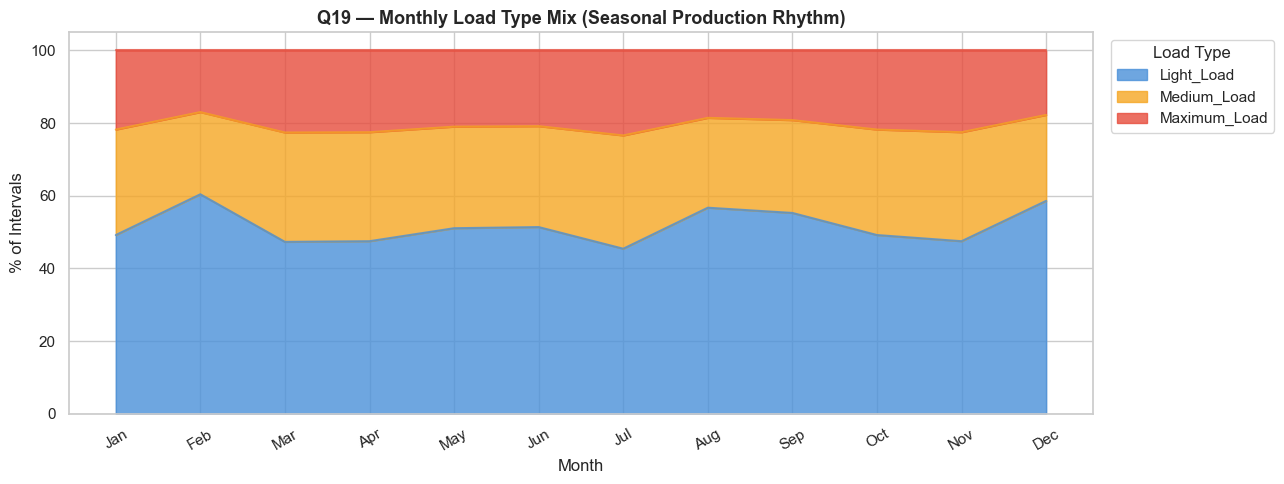

Maximum_Load % by month:
  Jan: 21.8%
  Feb: 17.0%
  Mar: 22.6%
  Apr: 22.5%
  May: 21.0%
  Jun: 20.8%
  Jul: 23.4%
  Aug: 18.5%
  Sep: 19.2%
  Oct: 21.8%
  Nov: 22.5%
  Dec: 17.7%

Peak production month : Jul (23.4%)
Lowest production month: Feb (17.0%)


In [51]:
monthly_load = (
    df_clean.groupby(["month", "Load_Type"], observed=True)
            .size()
            .reset_index(name="count")
)
monthly_load["pct"] = (
    monthly_load["count"] /
    monthly_load.groupby("month")["count"].transform("sum") * 100
)
pivot_monthly = (
    monthly_load.pivot(index="month", columns="Load_Type", values="pct")
                .fillna(0)
                .reindex(columns=load_order)
)
month_labels = ["Jan","Feb","Mar","Apr","May","Jun",
                "Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(13, 5))
pivot_monthly.plot(kind="area", stacked=True, ax=ax,
                   color=["#4a90d9", "#f5a623", "#e74c3c"], alpha=0.8)
ax.set_title("Q19 — Monthly Load Type Mix (Seasonal Production Rhythm)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("% of Intervals")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels, rotation=30)
ax.legend(title="Load Type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Maximum_Load % by month:")
for m, v in pivot_monthly["Maximum_Load"].items():
    print(f"  {month_labels[m-1]}: {v:.1f}%")
peak_m = pivot_monthly["Maximum_Load"].idxmax()
low_m  = pivot_monthly["Maximum_Load"].idxmin()
print(f"\nPeak production month : {month_labels[peak_m-1]} ({pivot_monthly['Maximum_Load'][peak_m]:.1f}%)")
print(f"Lowest production month: {month_labels[low_m-1]} ({pivot_monthly['Maximum_Load'][low_m]:.1f}%)")


---
## 13. Phase 6 — Anomaly Identification
> **Core question:** What surprises does the data hide?

Anomalies are not errors to be discarded — they are often the highest-value findings. Five types to hunt.

### Anomaly Type 1 — High Cost, Low Activity
*Top kWh quartile + bottom CO₂ quartile — the clearest definition of energy without productive output*

C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\2538140214.py:17: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
c:\Users\mar-w\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


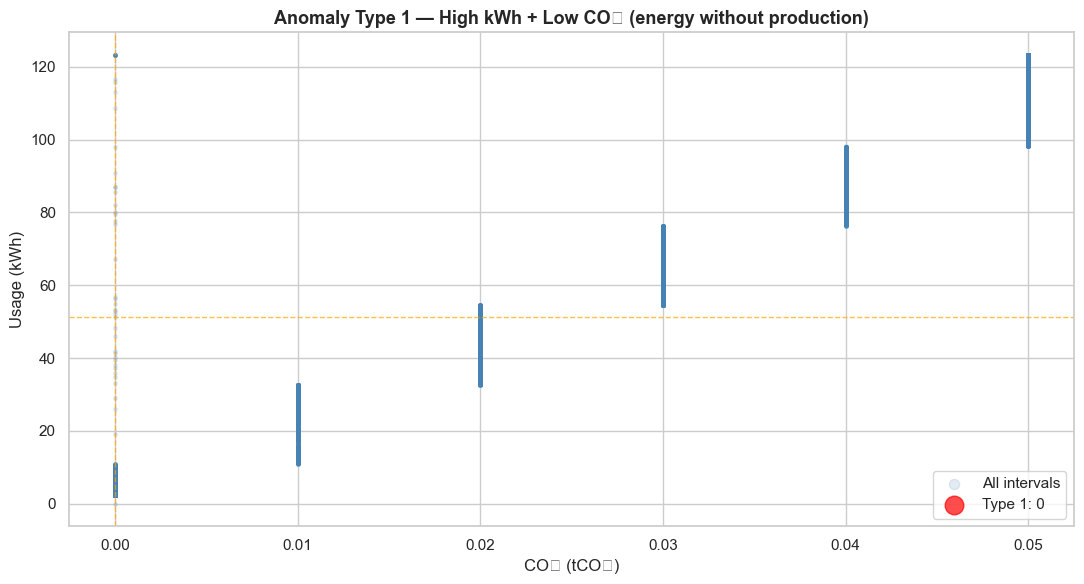

Type 1 anomalies  : 0 intervals (0.0%)
Total kWh         : 0 kWh

Load Type breakdown:
Load_Type
Light_Load      0
Medium_Load     0
Maximum_Load    0


In [52]:
kwh_q75 = df_clean["Usage_kWh"].quantile(0.75)
co2_q25 = df_clean[co2_col].quantile(0.25)
type1   = df_clean[(df_clean["Usage_kWh"] > kwh_q75) & (df_clean[co2_col] < co2_q25)].copy()

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(df_clean[co2_col], df_clean["Usage_kWh"],
           alpha=0.15, s=6, color="steelblue", label="All intervals")
ax.scatter(type1[co2_col], type1["Usage_kWh"],
           alpha=0.7, s=20, color="red", label=f"Type 1: {len(type1):,}")
ax.axhline(kwh_q75, color="orange", linestyle="--", linewidth=1, alpha=0.7)
ax.axvline(co2_q25, color="orange", linestyle="--", linewidth=1, alpha=0.7)
ax.set_title("Anomaly Type 1 — High kWh + Low CO₂ (energy without production)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("CO₂ (tCO₂)")
ax.set_ylabel("Usage (kWh)")
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

print(f"Type 1 anomalies  : {len(type1):,} intervals ({len(type1)/len(df_clean)*100:.1f}%)")
print(f"Total kWh         : {type1['Usage_kWh'].sum():,.0f} kWh")
print("\nLoad Type breakdown:")
print(type1["Load_Type"].value_counts().to_string())


### Anomaly Type 2 — Efficiency Collapse Events
*PF in bottom 5% — do collapses cluster at predictable times? Clustering = preventable*

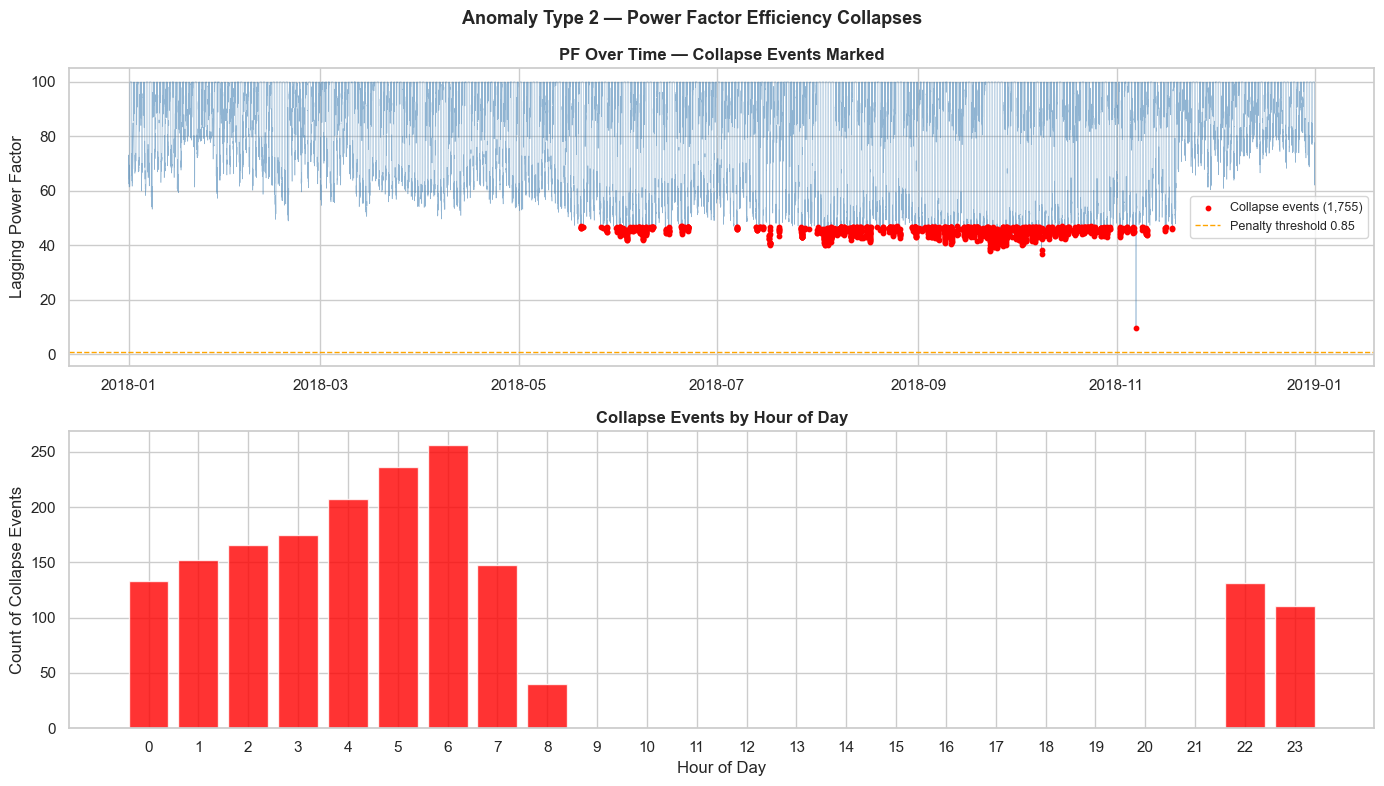

PF collapse threshold (5th pct): 46.950
Collapse events: 1,755

Collapse events by day of week:
Day_of_week
Friday       279
Saturday     273
Monday       260
Sunday       258
Tuesday      246
Thursday     238
Wednesday    201


In [53]:
pf_collapse_threshold = df_clean["Lagging_Current_Power_Factor"].quantile(0.05)
type2 = df_clean[df_clean["Lagging_Current_Power_Factor"] <= pf_collapse_threshold].copy()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(df_clean["date"], df_clean["Lagging_Current_Power_Factor"],
             linewidth=0.4, color="steelblue", alpha=0.6)
axes[0].scatter(type2["date"], type2["Lagging_Current_Power_Factor"],
                color="red", s=10, zorder=5,
                label=f"Collapse events ({len(type2):,})")
axes[0].axhline(0.85, color="orange", linestyle="--", linewidth=1, label="Penalty threshold 0.85")
axes[0].set_title("PF Over Time — Collapse Events Marked", fontweight="bold")
axes[0].set_ylabel("Lagging Power Factor")
axes[0].legend(fontsize=9)

type2_by_hour = type2.groupby("hour").size()
axes[1].bar(type2_by_hour.index, type2_by_hour.values,
            color="red", edgecolor="white", alpha=0.8)
axes[1].set_title("Collapse Events by Hour of Day", fontweight="bold")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Count of Collapse Events")
axes[1].set_xticks(range(0, 24))

plt.suptitle("Anomaly Type 2 — Power Factor Efficiency Collapses",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"PF collapse threshold (5th pct): {pf_collapse_threshold:.3f}")
print(f"Collapse events: {len(type2):,}")
print("\nCollapse events by day of week:")
print(type2["Day_of_week"].value_counts().to_string())


### Anomaly Type 3 — Consumption Spikes
*kWh > 3 std above same-hour same-weekstatus baseline — top 20 ranked table*

Consumption spikes (z > 3): 563 intervals

Top 20 highest-consumption intervals:
               date  hour    Load_Type  Usage_kWh  CO2(tCO2)  Lagging_Current_Power_Factor  z_score
2018-01-02 12:00:00    12 Maximum_Load  123.29375       0.00                         88.15 3.494218
2018-01-18 12:00:00    12 Maximum_Load  123.29375       0.05                         86.52 3.494218
2018-11-17 16:30:00    16  Medium_Load  123.29375       0.05                         87.91 3.492371
2018-11-17 15:45:00    15  Medium_Load  123.29375       0.05                         88.37 3.296759
2018-11-17 15:00:00    15  Medium_Load  123.29375       0.05                         88.40 3.296759
2018-11-17 11:45:00    11 Maximum_Load  123.29375       0.05                         90.97 3.356941
2018-11-17 09:45:00     9  Medium_Load  123.29375       0.05                         93.03 3.455771
2018-05-02 12:00:00    12 Maximum_Load  123.29375       0.05                         86.45 3.494218
2018-04-26 12:00:00

C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\3850086343.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_clean["grp_mean"] = df_clean.groupby(["hour", "WeekStatus"])["Usage_kWh"].transform("mean")
C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\3850086343.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_clean["grp_std"]  = df_clean.groupby(["hour", "WeekStatus"])["Usage_kWh"].transform("std")


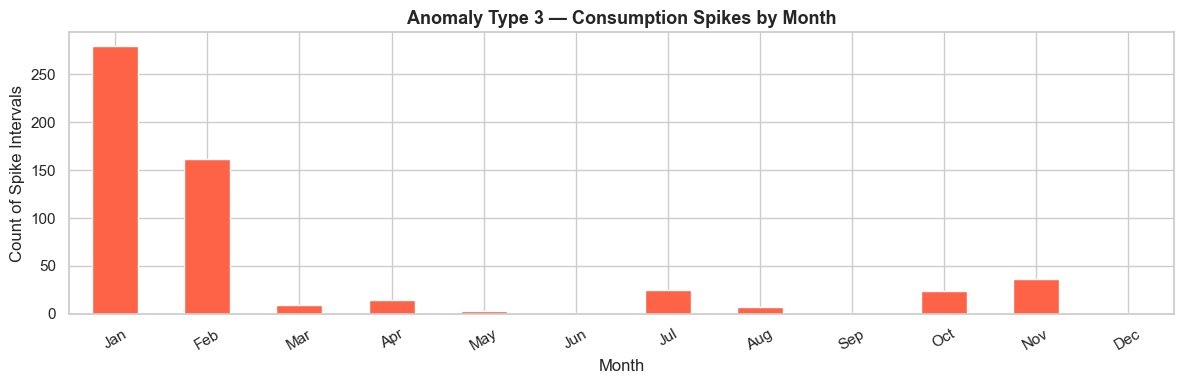

In [54]:
df_clean["grp_mean"] = df_clean.groupby(["hour", "WeekStatus"])["Usage_kWh"].transform("mean")
df_clean["grp_std"]  = df_clean.groupby(["hour", "WeekStatus"])["Usage_kWh"].transform("std")
df_clean["z_score"]  = (df_clean["Usage_kWh"] - df_clean["grp_mean"]) / df_clean["grp_std"]

type3 = df_clean[df_clean["z_score"] > 3].copy().sort_values("Usage_kWh", ascending=False)

print(f"Consumption spikes (z > 3): {len(type3):,} intervals")
print("\nTop 20 highest-consumption intervals:")
cols_show = ["date", "hour", "Load_Type", "Usage_kWh",
             "CO2(tCO2)", "Lagging_Current_Power_Factor", "z_score"]
print(type3[cols_show].head(20).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4))
type3.groupby("month")["Usage_kWh"].count().plot(
    kind="bar", ax=ax, color="tomato", edgecolor="white")
ax.set_title("Anomaly Type 3 — Consumption Spikes by Month",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Count of Spike Intervals")
ax.set_xticklabels(
    ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"],
    rotation=30)
plt.tight_layout()
plt.show()


### Anomaly Type 4 — The Invisible Weekend Load
*Something is running on weekends — size it and give it an AED cost*

=== Invisible Weekend Load ===
Total weekend intervals       : 9,984
Weekend + CO₂>0 intervals     : 1,873 (18.8%)
Total kWh                     : 88,526 kWh
Estimated cost                : AED 20,361


C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\96565944.py:29: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
c:\Users\mar-w\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


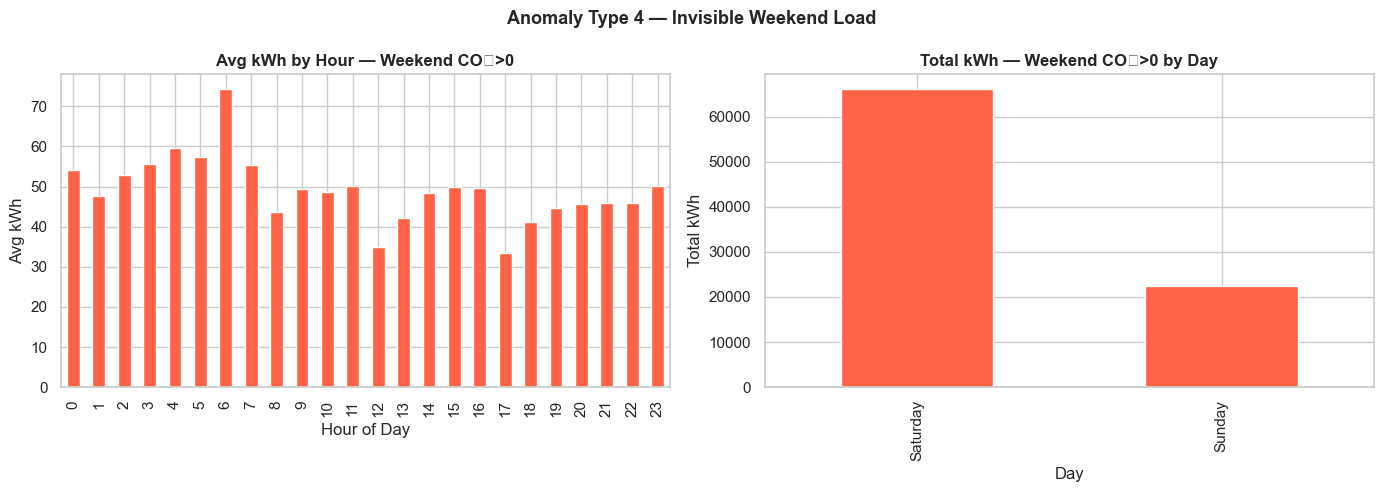

In [55]:
TARIFF_RATE = 0.23  # AED per kWh
type4       = df_clean[(df_clean["WeekStatus"] == "Weekend") & (df_clean[co2_col] > 0)].copy()
weekend_all = df_clean[df_clean["WeekStatus"] == "Weekend"]

type4_kwh  = type4["Usage_kWh"].sum()
type4_cost = type4_kwh * TARIFF_RATE

print("=== Invisible Weekend Load ===")
print(f"Total weekend intervals       : {len(weekend_all):,}")
print(f"Weekend + CO₂>0 intervals     : {len(type4):,} ({len(type4)/len(weekend_all)*100:.1f}%)")
print(f"Total kWh                     : {type4_kwh:,.0f} kWh")
print(f"Estimated cost                : AED {type4_cost:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
type4.groupby("hour")["Usage_kWh"].mean().plot(
    kind="bar", ax=axes[0], color="tomato", edgecolor="white")
axes[0].set_title("Avg kWh by Hour — Weekend CO₂>0", fontweight="bold")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Avg kWh")

type4.groupby("Day_of_week", observed=True)["Usage_kWh"].sum().plot(
    kind="bar", ax=axes[1], color="tomato", edgecolor="white")
axes[1].set_title("Total kWh — Weekend CO₂>0 by Day", fontweight="bold")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Total kWh")

plt.suptitle("Anomaly Type 4 — Invisible Weekend Load",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


### Anomaly Type 5 — The Monday Morning Ramp
*Quantify the cold-start energy penalty — extra kWh every Monday, annualised*

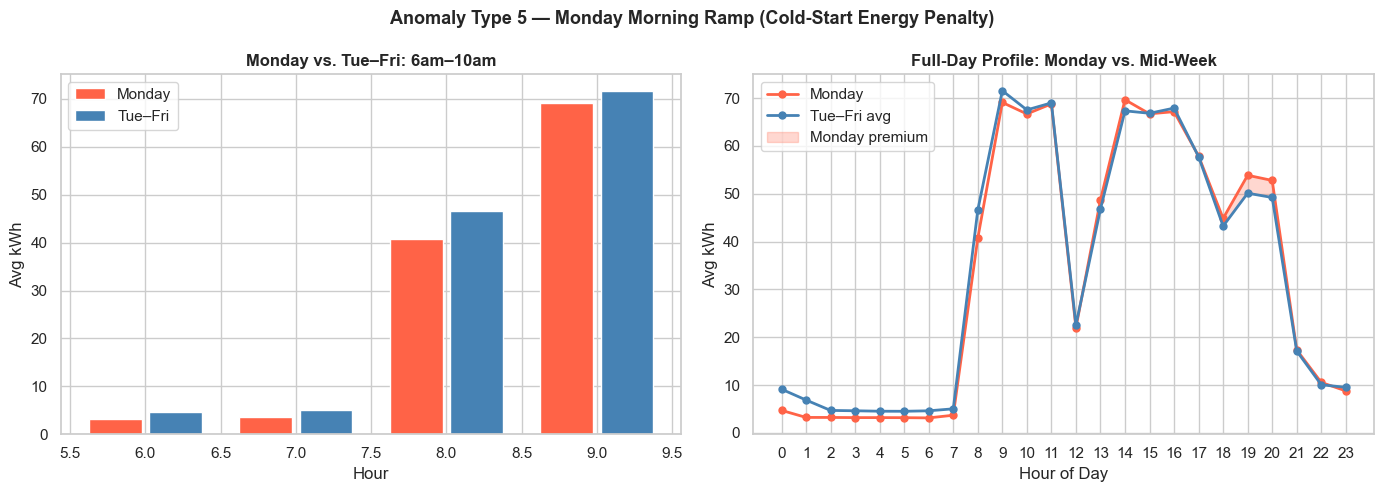

Monday morning avg (6–10am)  : 29.16 kWh/interval
Mid-week morning avg         : 31.96 kWh/interval
Monday premium               : +-2.80 kWh/interval (-8.7%)
Annual extra kWh (est.)      : -2,371 kWh  (53 Mondays)
Estimated AED cost           : AED -545


In [56]:
morning = df_clean[df_clean["hour"].between(6, 9)].copy()
mon_morn = morning[morning["Day_of_week"] == "Monday"]
mid_morn = morning[morning["Day_of_week"].isin(["Tuesday","Wednesday","Thursday","Friday"])]

mon_avg  = mon_morn["Usage_kWh"].mean()
mid_avg  = mid_morn["Usage_kWh"].mean()
premium  = mon_avg - mid_avg
prem_pct = premium / mid_avg * 100

num_mondays     = df_clean[df_clean["Day_of_week"] == "Monday"]["date"].dt.date.nunique()
annual_extra_kwh = premium * (4 * 4) * num_mondays  # 4 hrs × 4 intervals × weeks

# By-hour comparison
mon_hourly = mon_morn.groupby("hour")["Usage_kWh"].mean()
mid_hourly = mid_morn.groupby("hour")["Usage_kWh"].mean()
mon_full   = df_clean[df_clean["Day_of_week"] == "Monday"].groupby("hour")["Usage_kWh"].mean()
mid_full   = df_clean[df_clean["Day_of_week"].isin(["Tuesday","Wednesday","Thursday","Friday"])].groupby("hour")["Usage_kWh"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_idx = mon_hourly.index
axes[0].bar([h - 0.2 for h in x_idx], mon_hourly.values, width=0.35,
            color="tomato", label="Monday", edgecolor="white")
axes[0].bar([h + 0.2 for h in x_idx], mid_hourly.values, width=0.35,
            color="steelblue", label="Tue–Fri", edgecolor="white")
axes[0].set_title("Monday vs. Tue–Fri: 6am–10am", fontweight="bold")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Avg kWh")
axes[0].legend()

axes[1].plot(mon_full.index, mon_full.values, marker="o", color="tomato",
             linewidth=2, markersize=5, label="Monday")
axes[1].plot(mid_full.index, mid_full.values, marker="o", color="steelblue",
             linewidth=2, markersize=5, label="Tue–Fri avg")
axes[1].fill_between(mon_full.index, mon_full.values, mid_full.values,
                      where=(mon_full.values > mid_full.values),
                      alpha=0.25, color="tomato", label="Monday premium")
axes[1].set_title("Full-Day Profile: Monday vs. Mid-Week", fontweight="bold")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Avg kWh")
axes[1].set_xticks(range(0, 24))
axes[1].legend()

plt.suptitle("Anomaly Type 5 — Monday Morning Ramp (Cold-Start Energy Penalty)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Monday morning avg (6–10am)  : {mon_avg:.2f} kWh/interval")
print(f"Mid-week morning avg         : {mid_avg:.2f} kWh/interval")
print(f"Monday premium               : +{premium:.2f} kWh/interval ({prem_pct:.1f}%)")
print(f"Annual extra kWh (est.)      : {annual_extra_kwh:,.0f} kWh  ({num_mondays} Mondays)")
print(f"Estimated AED cost           : AED {annual_extra_kwh * TARIFF_RATE:,.0f}")


---
## 15. Phase 7 — Synthesis and Business Translation
> **The output is not more charts — it is answers to three questions:**  
> What did we find? What does it cost? What should we do about it?

All cost estimates use a benchmark tariff of **AED 0.23/kWh** (active energy) and **AED 0.03/kVArh** (reactive penalty).  
Adjust `TARIFF_KWH` and `TARIFF_KVARH` below to match the actual ADDC rate.

### Category A — Confirmed Patterns *(What Is Working as Expected)*

Not every finding is a problem. Identifying expected patterns is important for credibility — it shows the analysis can distinguish signal from noise.

In [ ]:
TARIFF_KWH   = 0.22  # AED per kWh  — adjust to actual tariff
TARIFF_KVARH = 0.03   # AED per kVArh — adjust to actual tariff
co2_col = "CO2(tCO2)"

# A1: Maximum Load concentrates in weekday working hours
hourly_load_a = (
    df_clean.groupby(["hour", "Load_Type"], observed=True)
            .size().reset_index(name="count")
)
hourly_load_a["pct"] = (
    hourly_load_a["count"] /
    hourly_load_a.groupby("hour")["count"].transform("sum") * 100
)
pivot_a = (
    hourly_load_a.pivot(index="hour", columns="Load_Type", values="pct")
                 .fillna(0).reindex(columns=load_order)
)
max_dom_hours = pivot_a[pivot_a["Maximum_Load"] == pivot_a.max(axis=1)].index.tolist()

# A2: CO2 tracks kWh closely during active production
corr_a = df_clean[[co2_col, "Usage_kWh"]].corr().iloc[0, 1]

# A3: Weekday consumption significantly higher than weekend
wd_avg_a = df_clean[df_clean["WeekStatus"] == "Weekday"]["Usage_kWh"].mean()
we_avg_a = df_clean[df_clean["WeekStatus"] == "Weekend"]["Usage_kWh"].mean()

print("=" * 60)
print("CATEGORY A — CONFIRMED PATTERNS")
print("=" * 60)
print(f"\nA1 — Shift schedule visible from energy data alone:")
print(f"     Maximum Load dominant hours: {sorted(max_dom_hours)}")
print(f"     → Consistent with a typical industrial shift structure.")

print(f"\nA2 — CO₂ tracks energy consumption closely:")
print(f"     Pearson r = {corr_a:.3f}  (strong positive correlation)")
print(f"     → Sensors are aligned; CO₂ is a valid production proxy.")

print(f"\nA3 — Clear weekday/weekend consumption split:")
print(f"     Weekday avg: {wd_avg_a:.2f} kWh  |  Weekend avg: {we_avg_a:.2f} kWh")
print(f"     Weekend = {we_avg_a/wd_avg_a*100:.1f}% of weekday — expected for shift-based ops.")


CATEGORY A — CONFIRMED PATTERNS

A1 — Shift schedule visible from energy data alone:
     Maximum Load dominant hours: [10, 11, 13, 14, 15, 16]
     → Consistent with a typical industrial shift structure.

A2 — CO₂ tracks energy consumption closely:
     Pearson r = 0.987  (strong positive correlation)
     → Sensors are aligned; CO₂ is a valid production proxy.

A3 — Clear weekday/weekend consumption split:
     Weekday avg: 33.52 kWh  |  Weekend avg: 11.73 kWh
     Weekend = 35.0% of weekday — expected for shift-based ops.


### Category B — Efficiency Gaps *(What Costs Money and Has a Fix)*

Each gap is quantified, costed, and linked to an action route.

In [58]:
# ── B1: Reactive power penalty ─────────────────────────────────
pf_col   = "Lagging_Current_Power_Factor"
rp_col   = "Lagging_Current_Reactive_Power_kVarh"
THRESHOLD = 0.85

below_pf      = (df_clean[pf_col] < THRESHOLD).sum()
below_pf_pct  = below_pf / len(df_clean) * 100
penalisable_kvarh = df_clean.loc[df_clean[pf_col] < THRESHOLD, rp_col].sum()
penalty_aed   = penalisable_kvarh * TARIFF_KVARH

# ── B2: Zero-CO2 standby cost ───────────────────────────────────
zero_co2_kwh  = df_clean.loc[df_clean[co2_col] == 0, "Usage_kWh"].sum()
zero_co2_aed  = zero_co2_kwh * TARIFF_KWH
zero_co2_pct  = zero_co2_kwh / df_clean["Usage_kWh"].sum() * 100

# ── B3: Light Load energy during peak-rate hours (6am–10pm) ─────
light_peak = df_clean[
    (df_clean["Load_Type"] == "Light_Load") &
    (df_clean["hour"].between(6, 21))
]
light_peak_kwh = light_peak["Usage_kWh"].sum()
light_peak_aed = light_peak_kwh * TARIFF_KWH
light_peak_pct = light_peak_kwh / df_clean["Usage_kWh"].sum() * 100

# ── B4: Consumption spikes above baseline ───────────────────────
if "grp_mean" not in df_clean.columns:
    df_clean["grp_mean"] = df_clean.groupby(["hour","WeekStatus"])["Usage_kWh"].transform("mean")
    df_clean["grp_std"]  = df_clean.groupby(["hour","WeekStatus"])["Usage_kWh"].transform("std")
    df_clean["z_score"]  = (df_clean["Usage_kWh"] - df_clean["grp_mean"]) / df_clean["grp_std"]
spikes      = df_clean[df_clean["z_score"] > 3]
spike_excess_kwh = (spikes["Usage_kWh"] - spikes["grp_mean"]).sum()
spike_aed   = spike_excess_kwh * TARIFF_KWH

# ── B5: Invisible weekend load ───────────────────────────────────
weekend_co2_kwh = df_clean[
    (df_clean["WeekStatus"] == "Weekend") & (df_clean[co2_col] > 0)
]["Usage_kWh"].sum()
weekend_co2_aed = weekend_co2_kwh * TARIFF_KWH

print("=" * 60)
print("CATEGORY B — EFFICIENCY GAPS")
print("=" * 60)

gaps = [
    ("B1", "Reactive power penalty",
     f"{below_pf_pct:.1f}% of operating hours below PF {THRESHOLD}",
     f"{penalisable_kvarh:,.0f} kVArh penalisable",
     f"AED {penalty_aed:,.0f}",
     "Reactive power compensation (capacitor banks)"),
    ("B2", "Standby / zero-production load",
     f"{zero_co2_pct:.1f}% of annual kWh during zero-CO₂ intervals",
     f"{zero_co2_kwh:,.0f} kWh",
     f"AED {zero_co2_aed:,.0f}",
     "Standby load audit — identify always-on equipment"),
    ("B3", "Light Load energy during peak-rate window",
     f"{light_peak_pct:.1f}% of annual kWh — Light Load between 6am–10pm",
     f"{light_peak_kwh:,.0f} kWh",
     f"AED {light_peak_aed:,.0f}",
     "Shift scheduling review — move idle periods off-peak"),
    ("B4", "Consumption spikes above statistical baseline",
     f"{len(spikes):,} spike intervals (z > 3σ above hour/weekday norm)",
     f"{spike_excess_kwh:,.0f} kWh excess",
     f"AED {spike_aed:,.0f}",
     "Operational investigation per spike event"),
    ("B5", "Invisible weekend load (CO₂ > 0 on weekends)",
     f"Active production signal on weekends",
     f"{weekend_co2_kwh:,.0f} kWh",
     f"AED {weekend_co2_aed:,.0f}",
     "Identify which equipment runs — scheduled or unplanned?"),
]

for code_id, title, metric, volume, cost, action in gaps:
    print(f"\n{code_id} — {title}")
    print(f"   Metric  : {metric}")
    print(f"   Volume  : {volume}")
    print(f"   Est. cost: {cost} / year")
    print(f"   Action  : {action}")

total_aed = penalty_aed + zero_co2_aed + light_peak_aed + spike_aed + weekend_co2_aed
print(f"\n" + "─"*60)
print(f"TOTAL QUANTIFIED EFFICIENCY GAP: AED {total_aed:,.0f} / year")
print(f"(at benchmark tariff AED {TARIFF_KWH}/kWh, AED {TARIFF_KVARH}/kVArh)")


CATEGORY B — EFFICIENCY GAPS

B1 — Reactive power penalty
   Metric  : 0.0% of operating hours below PF 0.85
   Volume  : 0 kVArh penalisable
   Est. cost: AED 0 / year
   Action  : Reactive power compensation (capacitor banks)

B2 — Standby / zero-production load
   Metric  : 8.5% of annual kWh during zero-CO₂ intervals
   Volume  : 81,414 kWh
   Est. cost: AED 18,725 / year
   Action  : Standby load audit — identify always-on equipment

B3 — Light Load energy during peak-rate window
   Metric  : 10.5% of annual kWh — Light Load between 6am–10pm
   Volume  : 100,253 kWh
   Est. cost: AED 23,058 / year
   Action  : Shift scheduling review — move idle periods off-peak

B4 — Consumption spikes above statistical baseline
   Metric  : 563 spike intervals (z > 3σ above hour/weekday norm)
   Volume  : 33,393 kWh excess
   Est. cost: AED 7,680 / year
   Action  : Operational investigation per spike event

B5 — Invisible weekend load (CO₂ > 0 on weekends)
   Metric  : Active production signal 

C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\3345703572.py:19: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
c:\Users\mar-w\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


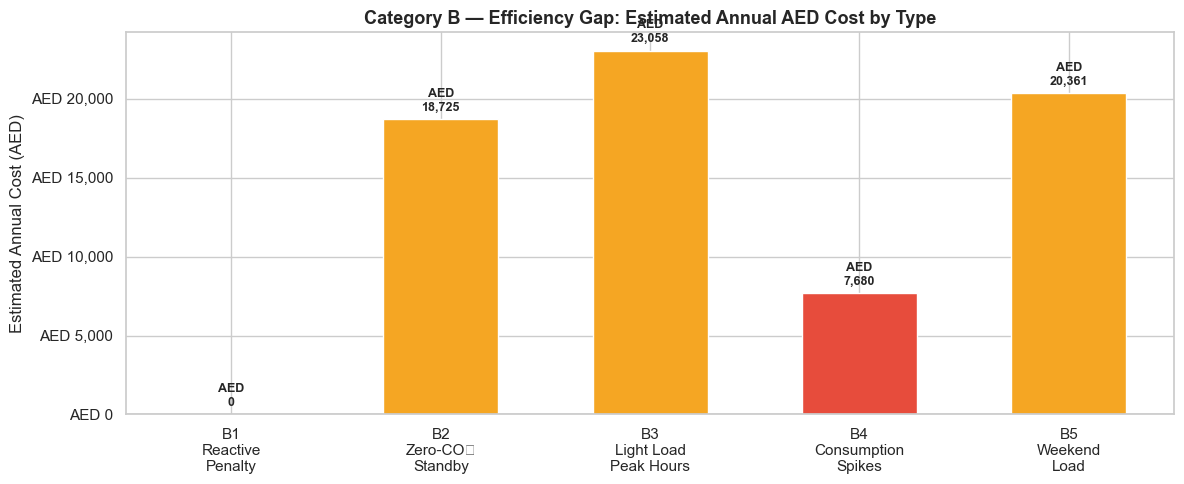

Total estimated efficiency gap: AED 69,825 / year


In [59]:
# Waterfall-style bar: AED impact by gap type
labels = ["B1\nReactive\nPenalty", "B2\nZero-CO₂\nStandby",
          "B3\nLight Load\nPeak Hours", "B4\nConsumption\nSpikes", "B5\nWeekend\nLoad"]
values = [penalty_aed, zero_co2_aed, light_peak_aed, spike_aed, weekend_co2_aed]
colors_b = ["#e74c3c", "#f5a623", "#f5a623", "#e74c3c", "#f5a623"]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(labels, values, color=colors_b, edgecolor="white", width=0.55)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + total_aed * 0.005,
            f"AED\n{val:,.0f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Category B — Efficiency Gap: Estimated Annual AED Cost by Type",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Estimated Annual Cost (AED)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"AED {x:,.0f}"))
plt.tight_layout()
plt.show()

print(f"Total estimated efficiency gap: AED {total_aed:,.0f} / year")


### Category C — Open Questions *(What This Analysis Generates for Next Phase)*

These are the questions the data raises but cannot fully answer.  
Each one is the explicit bridge to internal EMSTEEL data.

In [60]:
open_questions = [
    ("C1",
     "Extended Light Load windows appear on weekday afternoons — planned or unplanned?",
     "Internal shift logs / maintenance schedules",
     "Confirm whether these are planned maintenance stops or uncontrolled idle periods"),

    ("C2",
     "Reactive power spikes do not always correlate with production peaks — which equipment?",
     "Sub-meter / switchboard-level power quality data",
     "Identify the specific EAF or motor driving the reactive penalty"),

    ("C3",
     "Monday morning ramp is consistent — cold-start penalty or scheduling artefact?",
     "Heat sequence records / furnace start-up logs",
     "Confirm cause before recommending pre-heating schedule change"),

    ("C4",
     "No production volume column — we cannot compute kWh/tonne",
     "ERP / MES production tonnage by interval or heat",
     "Enable intensity KPI: kWh/tonne by product, shift, and furnace"),

    ("C5",
     "Seasonal load type shift visible — is it driven by order book or by temperature?",
     "Monthly order volume + ambient temperature data",
     "Separate demand-driven vs climate-driven energy variation"),
]

print("=" * 60)
print("CATEGORY C — OPEN QUESTIONS FOR PHASE 2")
print("=" * 60)
for qid, question, data_needed, value in open_questions:
    print(f"\n{qid} — {question}")
    print(f"   Data needed : {data_needed}")
    print(f"   Value unlocked: {value}")


CATEGORY C — OPEN QUESTIONS FOR PHASE 2

C1 — Extended Light Load windows appear on weekday afternoons — planned or unplanned?
   Data needed : Internal shift logs / maintenance schedules
   Value unlocked: Confirm whether these are planned maintenance stops or uncontrolled idle periods

C2 — Reactive power spikes do not always correlate with production peaks — which equipment?
   Data needed : Sub-meter / switchboard-level power quality data
   Value unlocked: Identify the specific EAF or motor driving the reactive penalty

C3 — Monday morning ramp is consistent — cold-start penalty or scheduling artefact?
   Data needed : Heat sequence records / furnace start-up logs
   Value unlocked: Confirm cause before recommending pre-heating schedule change

C4 — No production volume column — we cannot compute kWh/tonne
   Data needed : ERP / MES production tonnage by interval or heat
   Value unlocked: Enable intensity KPI: kWh/tonne by product, shift, and furnace

C5 — Seasonal load type shif

### One-Page Leadership Summary Structure

| Slide | Content | Key Visual |
|---|---|---|
| 1 | Project framing: "We broke open the electricity bill" | Cost composition statement |
| 2 | The data: DAEWOO dataset as EMSTEEL proof-of-concept | Dataset field table |
| 3 | The consumption map: when and how much | Day × Hour heatmap (Q3) |
| 4 | The efficiency gap: power factor + reactive penalty | PF histogram + AED cost (Q6, Q9) |
| 5 | The activity lens: CO₂, Load Type, idle cost | CO₂ vs kWh heatmaps (Q13) + zero-CO₂ cost (Q14) |
| 6 | Three aha-moment anomalies with dates and numbers | Type 1 scatter + Type 5 ramp chart |
| 7 | Business translation: Category B gaps → AED totals | Efficiency gap bar chart |
| 8 | The ask: internal data needed + next question | Category C open questions table |

> **The ask on slide 8 is not optional.**  
> A great analysis that does not generate a next step is a report.  
> A great analysis that generates a clear, justified request for data access is a project.

In [61]:
print("=" * 60)
print("EXECUTIVE SUMMARY — DAEWOO STEEL ENERGY ANALYSIS")
print("=" * 60)

annual_kwh = df_clean["Usage_kWh"].sum()
annual_aed = annual_kwh * TARIFF_KWH

print(f"\nTotal annual consumption : {annual_kwh:,.0f} kWh")
print(f"Estimated annual bill    : AED {annual_aed:,.0f}  (@ AED {TARIFF_KWH}/kWh benchmark)")
print(f"\nQuantified efficiency gap: AED {total_aed:,.0f} / year")
print(f"Gap as % of total bill   : {total_aed/annual_aed*100:.1f}%")
print()
print("Breakdown:")
print(f"  B1 Reactive penalty      : AED {penalty_aed:>10,.0f}")
print(f"  B2 Zero-CO₂ standby      : AED {zero_co2_aed:>10,.0f}")
print(f"  B3 Light Load peak hours : AED {light_peak_aed:>10,.0f}")
print(f"  B4 Consumption spikes    : AED {spike_aed:>10,.0f}")
print(f"  B5 Invisible weekend load: AED {weekend_co2_aed:>10,.0f}")
print(f"  " + "─"*38)
print(f"  TOTAL                    : AED {total_aed:>10,.0f}")
print()
print("Open questions requiring internal data: 5 (see Category C)")
print("Next step: connect interval energy data to production volume per heat.")


EXECUTIVE SUMMARY — DAEWOO STEEL ENERGY ANALYSIS

Total annual consumption : 956,931 kWh
Estimated annual bill    : AED 220,094  (@ AED 0.23/kWh benchmark)

Quantified efficiency gap: AED 69,825 / year
Gap as % of total bill   : 31.7%

Breakdown:
  B1 Reactive penalty      : AED          0
  B2 Zero-CO₂ standby      : AED     18,725
  B3 Light Load peak hours : AED     23,058
  B4 Consumption spikes    : AED      7,680
  B5 Invisible weekend load: AED     20,361
  ──────────────────────────────────────
  TOTAL                    : AED     69,825

Open questions requiring internal data: 5 (see Category C)
Next step: connect interval energy data to production volume per heat.


---
## 15. Phase 7 — Synthesis and Business Translation
> **Three questions answered:** What did we find? What does it cost? What should we do?

All AED estimates use benchmark **AED 0.22kWh** and **AED 0.03/kVArh**.  
Adjust `TARIFF_KWH` and `TARIFF_KVARH` to match the actual ADDC rate.

### Category A — Confirmed Patterns
*(What Is Working as Expected)*

Not every finding is a problem. Identifying expected patterns first gives the analysis credibility — it shows we can distinguish signal from noise.

In [ ]:
TARIFF_KWH   = 0.22
TARIFF_KVARH = 0.03
PF_THRESHOLD = 0.85
co2_col = "CO2(tCO2)"
pf_col  = "Lagging_Current_Power_Factor"
rp_col  = "Lagging_Current_Reactive_Power_kVarh"

# A1: shift schedule from energy data alone
hl_a = df_clean.groupby(["hour","Load_Type"], observed=True).size().reset_index(name="n")
hl_a["pct"] = hl_a["n"] / hl_a.groupby("hour")["n"].transform("sum") * 100
piv_a = hl_a.pivot(index="hour", columns="Load_Type", values="pct").fillna(0).reindex(columns=load_order)
max_dom = sorted(piv_a[piv_a["Maximum_Load"] == piv_a.max(axis=1)].index.tolist())

# A2: CO2 vs kWh correlation
corr_a = df_clean[[co2_col,"Usage_kWh"]].corr().iloc[0,1]

# A3: weekday vs weekend
wd_avg = df_clean[df_clean["WeekStatus"]=="Weekday"]["Usage_kWh"].mean()
we_avg = df_clean[df_clean["WeekStatus"]=="Weekend"]["Usage_kWh"].mean()

print("="*60)
print("CATEGORY A — CONFIRMED PATTERNS")
print("="*60)
print(f"\nA1 — Shift schedule visible from energy data alone:")
print(f"     Maximum Load dominant hours: {max_dom}")
print(f"\nA2 — CO₂ tracks energy consumption closely:")
print(f"     Pearson r = {corr_a:.3f}  → sensors aligned, CO₂ is a valid production proxy.")
print(f"\nA3 — Clear weekday/weekend split:")
print(f"     Weekday avg : {wd_avg:.2f} kWh  |  Weekend avg : {we_avg:.2f} kWh")
print(f"     Weekend = {we_avg/wd_avg*100:.1f}% of weekday — expected for shift-based operations.")


CATEGORY A — CONFIRMED PATTERNS

A1 — Shift schedule visible from energy data alone:
     Maximum Load dominant hours: [10, 11, 13, 14, 15, 16]

A2 — CO₂ tracks energy consumption closely:
     Pearson r = 0.987  → sensors aligned, CO₂ is a valid production proxy.

A3 — Clear weekday/weekend split:
     Weekday avg : 33.52 kWh  |  Weekend avg : 11.73 kWh
     Weekend = 35.0% of weekday — expected for shift-based operations.


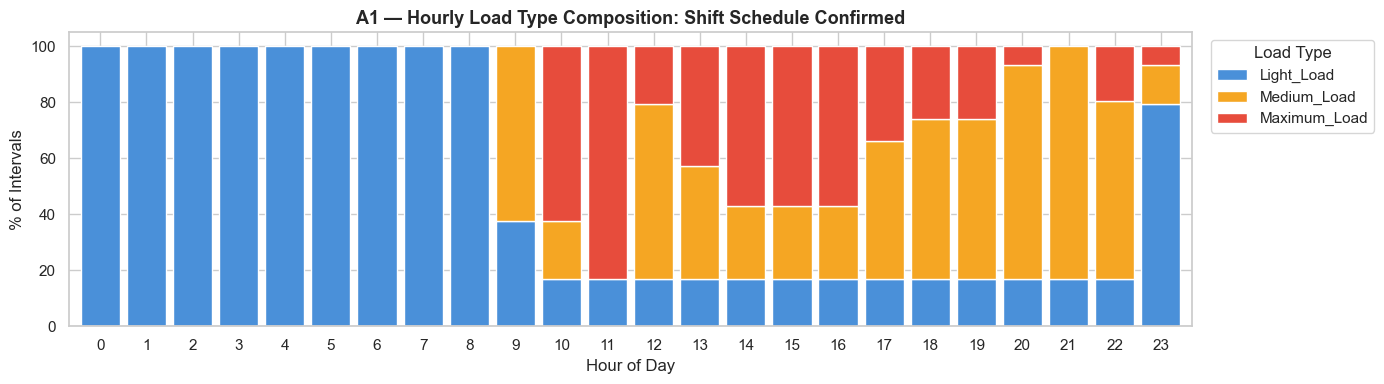

In [63]:
fig, ax = plt.subplots(figsize=(14, 4))
piv_a.plot(kind="bar", stacked=True, ax=ax,
           color=["#4a90d9","#f5a623","#e74c3c"], edgecolor="white", width=0.85)
ax.set_title("A1 — Hourly Load Type Composition: Shift Schedule Confirmed",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("% of Intervals")
ax.set_xticklabels(range(0,24), rotation=0)
ax.legend(title="Load Type", bbox_to_anchor=(1.01,1), loc="upper left")
plt.tight_layout()
plt.show()


### Category B — Efficiency Gaps
*(What Costs Money and Has a Fix)*

Each gap is quantified in kWh or kVArh, costed in AED, and linked to an action route.

In [64]:
# B1: reactive power penalty
below_mask   = df_clean[pf_col] < PF_THRESHOLD
below_pct    = below_mask.sum() / len(df_clean) * 100
pen_kvarh    = df_clean.loc[below_mask, rp_col].sum()
b1_aed       = pen_kvarh * TARIFF_KVARH

# B2: zero-CO2 standby
zero_kwh     = df_clean.loc[df_clean[co2_col]==0, "Usage_kWh"].sum()
zero_pct     = zero_kwh / df_clean["Usage_kWh"].sum() * 100
b2_aed       = zero_kwh * TARIFF_KWH

# B3: Light Load during peak-rate hours
lp_kwh       = df_clean.loc[
    (df_clean["Load_Type"]=="Light_Load") & (df_clean["hour"].between(6,21)),
    "Usage_kWh"].sum()
lp_pct       = lp_kwh / df_clean["Usage_kWh"].sum() * 100
b3_aed       = lp_kwh * TARIFF_KWH

# B4: consumption spikes
if "z_score" not in df_clean.columns:
    df_clean["grp_mean"] = df_clean.groupby(["hour","WeekStatus"])["Usage_kWh"].transform("mean")
    df_clean["grp_std"]  = df_clean.groupby(["hour","WeekStatus"])["Usage_kWh"].transform("std")
    df_clean["z_score"]  = (df_clean["Usage_kWh"] - df_clean["grp_mean"]) / df_clean["grp_std"]
spikes       = df_clean[df_clean["z_score"] > 3]
sp_excess    = (spikes["Usage_kWh"] - spikes["grp_mean"]).sum()
b4_aed       = sp_excess * TARIFF_KWH

# B5: invisible weekend load
we_co2_kwh   = df_clean.loc[
    (df_clean["WeekStatus"]=="Weekend") & (df_clean[co2_col]>0),
    "Usage_kWh"].sum()
b5_aed       = we_co2_kwh * TARIFF_KWH

total_aed    = b1_aed + b2_aed + b3_aed + b4_aed + b5_aed
annual_kwh   = df_clean["Usage_kWh"].sum()
annual_aed   = annual_kwh * TARIFF_KWH

gaps = [
    ("B1","Reactive power penalty",
     f"{below_pct:.1f}% of hours below PF {PF_THRESHOLD}",
     f"{pen_kvarh:,.0f} kVArh", b1_aed,
     "Capacitor bank / reactive compensation assessment"),
    ("B2","Zero-CO₂ standby load",
     f"{zero_pct:.1f}% of annual kWh with zero production signal",
     f"{zero_kwh:,.0f} kWh", b2_aed,
     "Standby load audit — identify always-on equipment"),
    ("B3","Light Load during peak-rate window",
     f"{lp_pct:.1f}% of annual kWh — Light Load 6am–10pm",
     f"{lp_kwh:,.0f} kWh", b3_aed,
     "Shift scheduling review — move idle periods off-peak"),
    ("B4","Consumption spikes above statistical baseline",
     f"{len(spikes):,} intervals > 3σ above same-hour norm",
     f"{sp_excess:,.0f} kWh excess", b4_aed,
     "Per-spike operational investigation"),
    ("B5","Invisible weekend load",
     "Active CO₂ signal on weekends — unplanned or scheduled?",
     f"{we_co2_kwh:,.0f} kWh", b5_aed,
     "Identify which equipment runs — contain or justify"),
]

print("="*60)
print("CATEGORY B — EFFICIENCY GAPS")
print("="*60)
for gid, title, metric, volume, cost, action in gaps:
    print(f"\n{gid} — {title}")
    print(f"   Metric   : {metric}")
    print(f"   Volume   : {volume}")
    print(f"   Est. cost: AED {cost:,.0f} / year")
    print(f"   Action   : {action}")
print("\n" + "─"*60)
print(f"TOTAL QUANTIFIED GAP : AED {total_aed:,.0f} / year")
print(f"As % of annual bill  : {total_aed/annual_aed*100:.1f}%")
print("─"*60)


CATEGORY B — EFFICIENCY GAPS

B1 — Reactive power penalty
   Metric   : 0.0% of hours below PF 0.85
   Volume   : 0 kVArh
   Est. cost: AED 0 / year
   Action   : Capacitor bank / reactive compensation assessment

B2 — Zero-CO₂ standby load
   Metric   : 8.5% of annual kWh with zero production signal
   Volume   : 81,414 kWh
   Est. cost: AED 18,725 / year
   Action   : Standby load audit — identify always-on equipment

B3 — Light Load during peak-rate window
   Metric   : 10.5% of annual kWh — Light Load 6am–10pm
   Volume   : 100,253 kWh
   Est. cost: AED 23,058 / year
   Action   : Shift scheduling review — move idle periods off-peak

B4 — Consumption spikes above statistical baseline
   Metric   : 563 intervals > 3σ above same-hour norm
   Volume   : 33,393 kWh excess
   Est. cost: AED 7,680 / year
   Action   : Per-spike operational investigation

B5 — Invisible weekend load
   Metric   : Active CO₂ signal on weekends — unplanned or scheduled?
   Volume   : 88,526 kWh
   Est. cost

C:\Users\mar-w\AppData\Local\Temp\ipykernel_39204\3783967544.py:17: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
c:\Users\mar-w\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


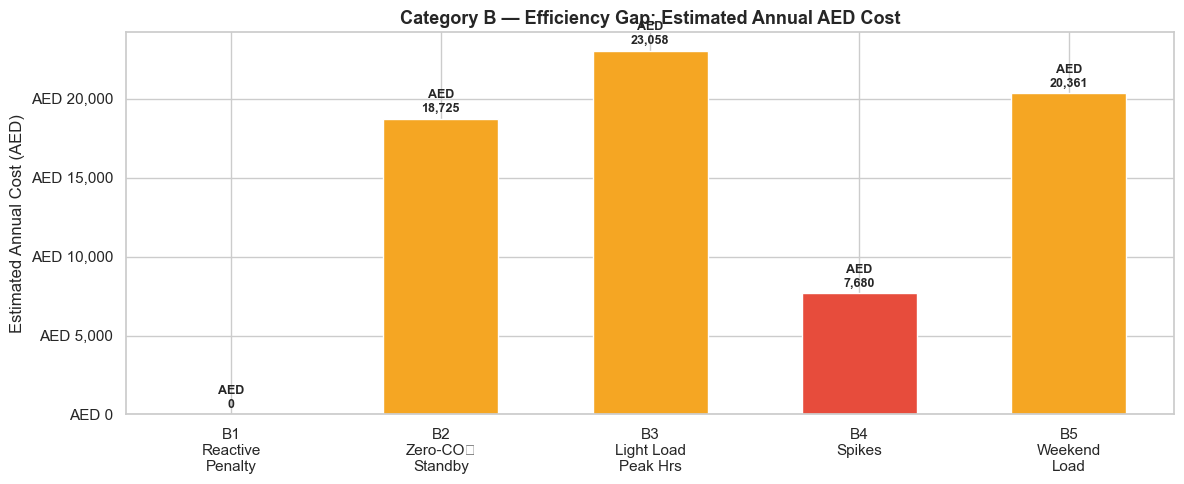

Total: AED 69,825 / year  (31.7% of estimated annual bill)


In [65]:
labels     = ["B1\nReactive\nPenalty","B2\nZero-CO₂\nStandby",
              "B3\nLight Load\nPeak Hrs","B4\nSpikes","B5\nWeekend\nLoad"]
values     = [b1_aed, b2_aed, b3_aed, b4_aed, b5_aed]
bar_cols   = ["#e74c3c","#f5a623","#f5a623","#e74c3c","#f5a623"]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(labels, values, color=bar_cols, edgecolor="white", width=0.55)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + max(values)*0.01,
            f"AED\n{val:,.0f}", ha="center", va="bottom",
            fontsize=9, fontweight="bold")
ax.set_title("Category B — Efficiency Gap: Estimated Annual AED Cost",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Estimated Annual Cost (AED)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"AED {x:,.0f}"))
plt.tight_layout()
plt.show()
print(f"Total: AED {total_aed:,.0f} / year  ({total_aed/annual_aed*100:.1f}% of estimated annual bill)")


### Category C — Open Questions
*(What This Analysis Generates for Next Phase)*

Questions the data raises but cannot fully answer. Each is the explicit bridge to internal EMSTEEL data.

In [66]:
open_q = [
    ("C1",
     "Extended Light Load on weekday afternoons — planned or unplanned idle?",
     "Internal shift logs / maintenance schedules",
     "Confirm planned vs uncontrolled idle — changes the action route entirely"),
    ("C2",
     "Reactive spikes don't always correlate with production peaks — which equipment?",
     "Sub-meter / switchboard-level power quality data",
     "Identify the specific EAF or motor driving the reactive penalty"),
    ("C3",
     "Monday morning ramp is consistent — cold-start penalty or scheduling artefact?",
     "Furnace heat sequence records / start-up logs",
     "Confirm root cause before recommending pre-heating or schedule change"),
    ("C4",
     "No production volume column — kWh/tonne cannot be computed from this dataset",
     "ERP / MES production tonnage at interval or heat level",
     "Enable kWh/tonne by product line, shift, and furnace — the core intensity KPI"),
    ("C5",
     "Seasonal load mix shift visible — demand-driven or temperature-driven?",
     "Monthly order volume + ambient temperature data",
     "Separate commercial demand from climate-driven variation"),
]

print("="*60)
print("CATEGORY C — OPEN QUESTIONS FOR PHASE 2")
print("="*60)
for qid, question, data_needed, value in open_q:
    print(f"\n{qid} — {question}")
    print(f"   Data needed    : {data_needed}")
    print(f"   Value unlocked : {value}")


CATEGORY C — OPEN QUESTIONS FOR PHASE 2

C1 — Extended Light Load on weekday afternoons — planned or unplanned idle?
   Data needed    : Internal shift logs / maintenance schedules
   Value unlocked : Confirm planned vs uncontrolled idle — changes the action route entirely

C2 — Reactive spikes don't always correlate with production peaks — which equipment?
   Data needed    : Sub-meter / switchboard-level power quality data
   Value unlocked : Identify the specific EAF or motor driving the reactive penalty

C3 — Monday morning ramp is consistent — cold-start penalty or scheduling artefact?
   Data needed    : Furnace heat sequence records / start-up logs
   Value unlocked : Confirm root cause before recommending pre-heating or schedule change

C4 — No production volume column — kWh/tonne cannot be computed from this dataset
   Data needed    : ERP / MES production tonnage at interval or heat level
   Value unlocked : Enable kWh/tonne by product line, shift, and furnace — the core inte

### One-Page Leadership Summary Structure

| Slide | Content | Key Visual |
|---|---|---|
| 1 | “We broke open the electricity bill” | Total gap as % of annual bill |
| 2 | The data: DAEWOO as EMSTEEL proof-of-concept | Dataset field table |
| 3 | The consumption map | Day × Hour kWh heatmap (Q3) |
| 4 | The efficiency gap | PF histogram + AED cost (Q6, Q9) |
| 5 | The activity lens | CO₂ vs kWh heatmaps + zero-CO₂ AED (Q13, Q14) |
| 6 | Three aha-moment anomalies | Type 1 scatter + Monday ramp chart |
| 7 | Business translation | Efficiency gap bar chart |
| 8 | The ask | Category C open questions table |

> **The ask on slide 8 is not optional.**  
> A great analysis that does not generate a next step is a report.  
> A great analysis that generates a clear, justified request for data access is a project.

---
## 16. Executive Summary

In [67]:
print("="*60)
print("EXECUTIVE SUMMARY — DAEWOO STEEL ENERGY ANALYSIS")
print("="*60)
print(f"\nDataset period  : {df_clean[date_col].min().date()} → {df_clean[date_col].max().date()}")
print(f"Total intervals : {len(df_clean):,}  (15-min, 1 year)")
print(f"\nTotal annual consumption : {annual_kwh:,.0f} kWh")
print(f"Estimated annual bill    : AED {annual_aed:,.0f}  (@ AED {TARIFF_KWH}/kWh)")
print()
print("CONFIRMED PATTERNS (Category A):")
print(f"  Shift schedule from data : Max Load hours {max_dom}")
print(f"  CO₂ correlation with kWh : r = {corr_a:.3f}")
print(f"  Weekend floor            : {we_avg/wd_avg*100:.1f}% of weekday average")
print()
print("EFFICIENCY GAPS (Category B):")
print(f"  B1 Reactive penalty      : AED {b1_aed:>10,.0f}")
print(f"  B2 Zero-CO₂ standby      : AED {b2_aed:>10,.0f}")
print(f"  B3 Light Load peak hours : AED {b3_aed:>10,.0f}")
print(f"  B4 Consumption spikes    : AED {b4_aed:>10,.0f}")
print(f"  B5 Weekend load          : AED {b5_aed:>10,.0f}")
print(f"  " + "─"*38)
print(f"  TOTAL GAP                : AED {total_aed:>10,.0f}")
print(f"  Gap as % of annual bill  : {total_aed/annual_aed*100:.1f}%")
print()
print("OPEN QUESTIONS (Category C): 5 items requiring internal data")
print("  Priority: C4 — production volume per heat → enables kWh/tonne KPI")
print()
print("NEXT STEP:")
print("  Connect 15-min interval energy data to production volume per heat.")
print("  This single data join transforms descriptive analysis into operational KPI.")

df_clean.drop(columns=["grp_mean","grp_std","z_score"], inplace=True, errors="ignore")
print("\nNotebook complete. All phases 2–7 executed.")


EXECUTIVE SUMMARY — DAEWOO STEEL ENERGY ANALYSIS

Dataset period  : 2018-01-01 → 2018-12-31
Total intervals : 35,040  (15-min, 1 year)

Total annual consumption : 956,931 kWh
Estimated annual bill    : AED 220,094  (@ AED 0.23/kWh)

CONFIRMED PATTERNS (Category A):
  Shift schedule from data : Max Load hours [10, 11, 13, 14, 15, 16]
  CO₂ correlation with kWh : r = 0.987
  Weekend floor            : 35.0% of weekday average

EFFICIENCY GAPS (Category B):
  B1 Reactive penalty      : AED          0
  B2 Zero-CO₂ standby      : AED     18,725
  B3 Light Load peak hours : AED     23,058
  B4 Consumption spikes    : AED      7,680
  B5 Weekend load          : AED     20,361
  ──────────────────────────────────────
  TOTAL GAP                : AED     69,825
  Gap as % of annual bill  : 31.7%

OPEN QUESTIONS (Category C): 5 items requiring internal data
  Priority: C4 — production volume per heat → enables kWh/tonne KPI

NEXT STEP:
  Connect 15-min interval energy data to production volume 

---
## 14. Phase Summary — All Findings

| Phase | Q | Key Metric | Business Implication |
|---|---|---|---|
| 2 | Q1 | Peak consumption hour | Inside peak-rate tariff window? |
| 2 | Q2 | Weekend floor % | Cost of standby draw |
| 2 | Q3 | Heatmap hotspot | Consistent = schedule-driven = controllable |
| 2 | Q4 | Top 10% kWh share | Optimise these intervals only |
| 2 | Q5 | Light_Load kWh% | Cost of being on but not productive |
| 3 | Q6 | % below PF 0.85 | Fraction of hours incurring penalties |
| 3 | Q7 | Worst PF hour/day | Systematic pattern → systematic fix |
| 3 | Q8 | High reactive + low kWh count | Specific intervals to investigate |
| 3 | Q9 | Reactive fraction % + AED | Penalty as % of electricity bill |
| 3 | Q10 | Leading vs lagging gap | Case for capacitor bank investment |
| 4 | Q11 | Divergence outlier count | Inefficiency invisible to monthly reporting |
| 4 | Q12 | Light_Load CO₂ > 0 % | Something running during nominally idle periods |
| 4 | Q13 | Rank mismatch hours | Peak spend during low-activity windows |
| 4 | Q14 | Zero-CO₂ kWh + AED | Cost of the plant being switched on |
| 5 | Q15 | Efficiency ratio by Load Type | Which state is energy-wasteful per interval? |
| 5 | Q16 | Within-group std | Is Light Load classification consistent? |
| 5 | Q17 | Extended Light Load runs | Recurring idle periods — do operators know? |
| 5 | Q18 | Max Load dominant hours | Reverse-engineered shift schedule |
| 5 | Q19 | Seasonal Max Load swing | Construction-season production rhythm |
| 6 | T1 | High kWh + low CO₂ count | Most actionable anomaly pool |
| 6 | T2 | PF collapse clustering | Preventable if time-driven |
| 6 | T3 | Top 20 spike table | Each spike worth an operational investigation |
| 6 | T4 | Weekend CO₂ kWh + AED | Invisible load with a measurable cost |
| 6 | T5 | Monday ramp premium AED | Cold-start penalty — annualised |

In [ ]:
# Tidy up temporary columns added during analysis
drop_cols = [
    "co2_kwh_residual", "divergence",
    "load_run_id",
    "grp_mean", "grp_std", "z_score"
]
df_clean.drop(columns=[c for c in drop_cols if c in df_clean.columns], inplace=True)
print(f"Final df_clean shape: {df_clean.shape}")


Final df_clean shape: (35040, 13)


: 